In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Cleaning

In [2]:
df = pd.read_csv('survey_results_public.csv')
df.head()

,ResponseId,Q120,MainBranch,Age,Employment,RemoteWork,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,ProfessionalTech,Industry,SurveyLength,SurveyEase,ConvertedCompYearly
0,1,I agree,None of these,18-24 years old,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I agree,I am a developer by profession,25-34 years old,"Employed, full-time",Remote,Hobby;Contribute to open-source projects;Boots...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;Friend or fam...,Formal documentation provided by the owner of ...,...,1-2 times a week,10+ times a week,Never,15-30 minutes a day,15-30 minutes a day,DevOps function;Microservices;Automated testin...,"Information Services, IT, Software Development...",Appropriate in length,Easy,285000.0
2,3,I agree,I am a developer by profession,45-54 years old,"Employed, full-time","Hybrid (some remote, some in-person)",Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Formal documentation provided by the owner of ...,...,6-10 times a week,6-10 times a week,3-5 times a week,30-60 minutes a day,30-60 minutes a day,DevOps function;Microservices;Automated testin...,"Information Services, IT, Software Development...",Appropriate in length,Easy,250000.0
3,4,I agree,I am a developer by profession,25-34 years old,"Employed, full-time","Hybrid (some remote, some in-person)",Hobby,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Friend or family member;Other online...,Formal documentation provided by the owner of ...,...,1-2 times a week,10+ times a week,1-2 times a week,15-30 minutes a day,30-60 minutes a day,Automated testing;Continuous integration (CI) ...,NaN,Appropriate in length,Easy,156000.0
4,5,I agree,I am a developer by profession,25-34 years old,"Employed, full-time;Independent contractor, fr...",Remote,Hobby;Contribute to open-source projects;Profe...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Online Courses or Certi...,Formal documentation provided by the owner of ...,...,1-2 times a week,1-2 times a week,3-5 times a week,60-120 minutes a day,30-60 minutes a day,Microservices;Automated testing;Observability ...,Other,Appropriate in length,Neither easy nor difficult,23456.0


In [3]:
pd.set_option('display.max_rows', 1000) 

In [4]:
df.isnull().sum()

ResponseId                                 0
Q120                                       0
MainBranch                                 0
Age                                        0
Employment                              1286
RemoteWork                             15374
CodingActivities                       15420
EdLevel                                 1211
LearnCode                               1521
LearnCodeOnline                        19100
LearnCodeCoursesCert                   52108
YearsCode                               1749
YearsCodePro                           23048
DevType                                12312
OrgSize                                24141
PurchaseInfluence                      24220
TechList                               28333
BuyNewTool                              6175
Country                                 1211
Currency                               23850
CompTotal                              40959
LanguageHaveWorkedWith                  2044
LanguageWa

In [5]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
Q120   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   27.068756727664155
PurchaseInfluence   27.157337639038392
TechList   31.769151417294584
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   26.742465016146394
CompTotal   45.926399354144245
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
DatabaseWantToWorkWith   31.701874775744525
PlatformHaveWorkedWith   28.655364190886257
PlatformWantToWorkWith   42.46950125583064
WebframeHaveWorkedWith   24.94393613204162
WebframeWantToWorkWith   36.37760136347327
MiscTechHaveWorkedWith   36.06588625762468
MiscTec

In [6]:
unnecessary_cols = ['Q120','SurveyEase','SurveyLength']

In [7]:
j = 0
delete_cols = []
for i in df.isnull().sum():
    p = (i/len(df)*100)
    if p >= 30:
        delete_cols.append(df.columns[j])
    j = j+1
delete_cols

['LearnCodeCoursesCert',
 'TechList',
 'CompTotal',
 'DatabaseWantToWorkWith',
 'PlatformWantToWorkWith',
 'WebframeWantToWorkWith',
 'MiscTechHaveWorkedWith',
 'MiscTechWantToWorkWith',
 'OfficeStackAsyncWantToWorkWith',
 'AISearchHaveWorkedWith',
 'AISearchWantToWorkWith',
 'AIDevHaveWorkedWith',
 'AIDevWantToWorkWith',
 'SOAI',
 'AISent',
 'AIAcc',
 'AIBen',
 'AIToolInterested in Using',
 'AIToolCurrently Using',
 'AIToolNot interested in Using',
 'AINextVery different',
 'AINextNeither different nor similar',
 'AINextSomewhat similar',
 'AINextVery similar',
 'AINextSomewhat different',
 'ICorPM',
 'WorkExp',
 'Knowledge_1',
 'Knowledge_2',
 'Knowledge_3',
 'Knowledge_4',
 'Knowledge_5',
 'Knowledge_6',
 'Knowledge_7',
 'Knowledge_8',
 'Frequency_1',
 'Frequency_2',
 'Frequency_3',
 'TimeSearching',
 'TimeAnswering',
 'ProfessionalTech',
 'Industry',
 'ConvertedCompYearly']

In [8]:
delete_cols.remove('CompTotal')
delete_cols.remove('LearnCodeCoursesCert')
for i in unnecessary_cols:
    delete_cols.append(i)
delete_cols

['TechList',
 'DatabaseWantToWorkWith',
 'PlatformWantToWorkWith',
 'WebframeWantToWorkWith',
 'MiscTechHaveWorkedWith',
 'MiscTechWantToWorkWith',
 'OfficeStackAsyncWantToWorkWith',
 'AISearchHaveWorkedWith',
 'AISearchWantToWorkWith',
 'AIDevHaveWorkedWith',
 'AIDevWantToWorkWith',
 'SOAI',
 'AISent',
 'AIAcc',
 'AIBen',
 'AIToolInterested in Using',
 'AIToolCurrently Using',
 'AIToolNot interested in Using',
 'AINextVery different',
 'AINextNeither different nor similar',
 'AINextSomewhat similar',
 'AINextVery similar',
 'AINextSomewhat different',
 'ICorPM',
 'WorkExp',
 'Knowledge_1',
 'Knowledge_2',
 'Knowledge_3',
 'Knowledge_4',
 'Knowledge_5',
 'Knowledge_6',
 'Knowledge_7',
 'Knowledge_8',
 'Frequency_1',
 'Frequency_2',
 'Frequency_3',
 'TimeSearching',
 'TimeAnswering',
 'ProfessionalTech',
 'Industry',
 'ConvertedCompYearly',
 'Q120',
 'SurveyEase',
 'SurveyLength']

In [9]:
df.drop(delete_cols, inplace=True, axis=1)

In [10]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   27.068756727664155
PurchaseInfluence   27.157337639038392
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   26.742465016146394
CompTotal   45.926399354144245
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
ToolsTechHaveWorkedWith   12.67043415859347
ToolsTechWantToWorkWith   23.399937208467886
NEWCollabToolsHaveWorkedWith   3.7226408324363116
NEWCollabToolsWantToWorkWith   14.05521169716541
OpSysPersonal use   2.94559562253

In [11]:
len(df['Employment'].unique())

107

In [12]:
fillEmpTypes = []
for i in df['Employment'].unique():
    if len(df[df['Employment'] == i]['CompTotal'].unique()) == 1:
        fillEmpTypes.append(i)
len(fillEmpTypes)
        

92

In [13]:
for i in fillEmpTypes:
    print(df[df['Employment']== i]['CompTotal'].unique())

[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
[nan]


In [14]:
df['CompTotal'] = df.apply(lambda x: 0 if x['Employment'] in fillEmpTypes and str(x['CompTotal']) == 'nan' 
                           else x['CompTotal'], axis=1)
df['CompTotal']

0                 NaN
1        2.850000e+05
2        2.500000e+05
3        1.560000e+05
4        1.320000e+06
             ...     
89179    2.000000e+05
89180    0.000000e+00
89181             NaN
89182    0.000000e+00
89183    3.300000e+09
Name: CompTotal, Length: 89184, dtype: float64

In [15]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   27.068756727664155
PurchaseInfluence   27.157337639038392
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   26.742465016146394
CompTotal   24.587369931826338
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
ToolsTechHaveWorkedWith   12.67043415859347
ToolsTechWantToWorkWith   23.399937208467886
NEWCollabToolsHaveWorkedWith   3.7226408324363116
NEWCollabToolsWantToWorkWith   14.05521169716541
OpSysPersonal use   2.94559562253

In [16]:
fillEmpTypes

['Not employed, but looking for work',
 'Student, full-time',
 'Independent contractor, freelancer, or self-employed;Employed, part-time;Student, part-time',
 'Not employed, but looking for work;Student, full-time',
 'Employed, part-time;Student, part-time',
 'Student, full-time;Employed, part-time',
 'Employed, full-time;Student, part-time',
 'Not employed, but looking for work;Employed, part-time',
 'Employed, full-time;Independent contractor, freelancer, or self-employed;Student, part-time',
 'Employed, full-time;Student, full-time',
 'Student, full-time;Student, part-time',
 'Independent contractor, freelancer, or self-employed;Student, full-time',
 'Not employed, and not looking for work',
 'Student, part-time',
 'Student, full-time;Not employed, and not looking for work',
 'Employed, full-time;Independent contractor, freelancer, or self-employed;Not employed, but looking for work',
 'Employed, full-time;Independent contractor, freelancer, or self-employed;Not employed, but lookin

In [17]:
df['Employment'] = df['Employment'].apply(lambda x: 'Not Employed' if x in fillEmpTypes else x)
df['Employment'].unique()

array([nan, 'Employed, full-time',
       'Employed, full-time;Independent contractor, freelancer, or self-employed',
       'Not Employed',
       'Independent contractor, freelancer, or self-employed',
       'Employed, part-time', 'I prefer not to say',
       'Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time',
       'Retired', 'Employed, full-time;Employed, part-time',
       'Independent contractor, freelancer, or self-employed;Employed, part-time',
       'Independent contractor, freelancer, or self-employed;Employed, part-time;Retired',
       'Independent contractor, freelancer, or self-employed;Retired',
       'Employed, full-time;Retired', 'Employed, part-time;Retired',
       'Employed, full-time;Independent contractor, freelancer, or self-employed;Retired'],
      dtype=object)

In [18]:
df[df['Employment']=='Retired']['CompTotal'].unique()

array([     nan, 1.90e+04, 0.00e+00, 1.25e+05, 2.00e+05, 2.50e+02,
       1.50e+06, 7.00e+04, 6.50e+04, 1.80e+07, 1.40e+05, 5.00e+05,
       1.85e+05, 3.50e+04, 1.41e+05, 1.00e+02, 2.40e+05, 1.20e+07,
       1.20e+05, 5.00e+04, 6.00e+04, 4.20e+04, 8.00e+07, 3.70e+03,
       1.00e+05, 1.00e+04, 1.28e+05, 1.30e+05, 9.50e+04, 3.00e+04])

In [19]:
df['Employment'] = df['Employment'].apply(lambda x: 'Employed' if str(x) not in ['Not Employed','nan'] else x)
df['Employment'].unique()

array([nan, 'Employed', 'Not Employed'], dtype=object)

In [20]:
df[(df['Currency'].isna())&(df['Country'].notna())&(df['CompTotal'].notna())][['Currency','Country','CompTotal']]

,Currency,Country,CompTotal
9,NaN,India,0.0
46,NaN,Sweden,0.0
49,NaN,Australia,0.0
52,NaN,Poland,0.0
53,NaN,United Kingdom of Great Britain and Northern I...,0.0
...,...,...,...
89168,NaN,France,0.0
89173,NaN,Trinidad and Tobago,0.0
89176,NaN,Greece,0.0
89180,NaN,Romania,0.0


In [21]:
df[df['Currency'].isna()]['CompTotal'].unique()

array([nan,  0.])

In [22]:
df['Currency'] = df['Currency'].apply(lambda x: 'No CompTotal' if str(x) in ['nan','0'] else x )
df['Currency'].unique()

array(['No CompTotal', 'USD\tUnited States dollar',
       'PHP\tPhilippine peso', 'GBP\tPound sterling', 'EUR European Euro',
       'AUD\tAustralian dollar', 'SEK\tSwedish krona',
       'AMD\tArmenian dram', 'ZAR\tSouth African rand',
       'BRL\tBrazilian real', 'BDT\tBangladeshi taka',
       'CAD\tCanadian dollar', 'CHF\tSwiss franc',
       'LKR\tSri Lankan rupee', 'INR\tIndian rupee', 'IRR\tIranian rial',
       'PLN\tPolish zloty', 'RUB\tRussian ruble', 'TRY\tTurkish lira',
       'DKK\tDanish krone', 'ILS\tIsraeli new shekel',
       'HUF\tHungarian forint', 'SGD\tSingapore dollar',
       'AED United Arab Emirates dirham', 'NOK\tNorwegian krone',
       'RSD\tSerbian dinar', 'CZK\tCzech koruna', 'NPR\tNepalese rupee',
       'RON\tRomanian leu', 'CNY\tChinese Yuan Renminbi',
       'SAR\tSaudi Arabian riyal', 'TND\tTunisian dinar',
       'KRW\tSouth Korean won', 'VND\tVietnamese dong',
       'UAH\tUkrainian hryvnia', 'DOP\tDominican peso',
       'EGP\tEgyptian pound', 'U

In [23]:
'''from google_currency import convert
curr_d = {}
curr_rem = []
for i in df['Currency'].unique()[2:]:
    response = convert(i[0:3],'USD',1)
    if response.split('"converted": ')[1][0:4]== 'true':
        print(response)
        ind = response.split('"amount": "')[1].index(',')
        curr_d[i[0:3]] = response.split('"amount": "')[1][0:ind-1]
    else:
        curr_rem.append(i[0:3])
curr_d'''

'from google_currency import convert\ncurr_d = {}\ncurr_rem = []\nfor i in df[\'Currency\'].unique()[2:]:\n    response = convert(i[0:3],\'USD\',1)\n    if response.split(\'"converted": \')[1][0:4]== \'true\':\n        print(response)\n        ind = response.split(\'"amount": "\')[1].index(\',\')\n        curr_d[i[0:3]] = response.split(\'"amount": "\')[1][0:ind-1]\n    else:\n        curr_rem.append(i[0:3])\ncurr_d'

In [24]:
'''curr_d['VES'] = 0.02743
curr_d['MNT'] = 0.00030
curr_d['SYP'] = 0.0011
curr_d['ERN'] = 0.06667
curr_d['MRU'] = 0.025
curr_d['FKP'] = 1.2808164436
curr_d['SLL'] = 0.000048
curr_d['IMP'] = 1.2788
curr_d['non'] = 0.15
curr_d['JEP'] = 1.28075
len(curr_d)'''

"curr_d['VES'] = 0.02743\ncurr_d['MNT'] = 0.00030\ncurr_d['SYP'] = 0.0011\ncurr_d['ERN'] = 0.06667\ncurr_d['MRU'] = 0.025\ncurr_d['FKP'] = 1.2808164436\ncurr_d['SLL'] = 0.000048\ncurr_d['IMP'] = 1.2788\ncurr_d['non'] = 0.15\ncurr_d['JEP'] = 1.28075\nlen(curr_d)"

In [25]:
import pickle
with open('currency_conversion.pkl', 'rb') as f:
    curr_d = pickle.load(f)
curr_d

{'PHP': '0.017',
 'GBP': '1.29',
 'EUR': '1.09',
 'AUD': '0.67',
 'SEK': '0.094',
 'AMD': '0.0026',
 'ZAR': '0.055',
 'BRL': '0.18',
 'BDT': '0.0085',
 'CAD': '0.73',
 'CHF': '1.13',
 'LKR': '0.0033',
 'INR': '0.012',
 'IRR': '0.000024',
 'PLN': '0.25',
 'RUB': '0.011',
 'TRY': '0.030',
 'DKK': '0.15',
 'ILS': '0.27',
 'HUF': '0.0028',
 'SGD': '0.74',
 'AED': '0.27',
 'NOK': '0.091',
 'RSD': '0.0093',
 'CZK': '0.043',
 'NPR': '0.0075',
 'RON': '0.22',
 'CNY': '0.14',
 'SAR': '0.27',
 'TND': '0.32',
 'KRW': '0.00072',
 'VND': '0.000039',
 'UAH': '0.024',
 'DOP': '0.017',
 'EGP': '0.021',
 'UZS': '0.000079',
 'ISK': '0.0073',
 'BGN': '0.56',
 'PKR': '0.0036',
 'IDR': '0.000062',
 'GEL': '0.37',
 'XOF': '0.0017',
 'QAR': '0.2731437424',
 'BHD': '2.65',
 'TJS': '0.094',
 'ARS': '0.0011',
 'COP': '0.00025',
 'BTN': '0.012',
 'BYN': '0.31',
 'OMR': '2.60',
 'BAM': '0.56',
 'MYR': '0.2138351331',
 'LBP': '0.000011',
 'ALL': '0.011',
 'NGN': '0.00061',
 'KES': '0.0077',
 'AFN': '0.014',
 'MAD'

In [26]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   27.068756727664155
PurchaseInfluence   27.157337639038392
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   0.0
CompTotal   24.587369931826338
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
ToolsTechHaveWorkedWith   12.67043415859347
ToolsTechWantToWorkWith   23.399937208467886
NEWCollabToolsHaveWorkedWith   3.7226408324363116
NEWCollabToolsWantToWorkWith   14.05521169716541
OpSysPersonal use   2.94559562253319
OpSysProfes

In [27]:
df[(df['CompTotal'].isna()) & (df['Employment'] == 'Employed')][['Employment','YearsCode','YearsCodePro','CompTotal']]

,Employment,YearsCode,YearsCodePro,CompTotal
10,Employed,14,3,NaN
26,Employed,16,9,NaN
27,Employed,20,10,NaN
35,Employed,5,NaN,NaN
41,Employed,10,5,NaN
...,...,...,...,...
89163,Employed,8,5,NaN
89164,Employed,6,2,NaN
89165,Employed,6,3,NaN
89169,Employed,15,15,NaN


In [28]:
df['CompTotal'] = df.apply(lambda x: 0 if x['Employment'] == 'Employed' and str(x['CompTotal']) == 'nan' 
                           else x['CompTotal'], axis=1)

In [29]:
df[(df['CompTotal'].isna()) & (df['Employment'] == 'Employed')][['Employment','YearsCode','YearsCodePro','CompTotal']]

,Employment,YearsCode,YearsCodePro,CompTotal


In [30]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   27.068756727664155
PurchaseInfluence   27.157337639038392
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   0.0
CompTotal   1.428507355579476
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
ToolsTechHaveWorkedWith   12.67043415859347
ToolsTechWantToWorkWith   23.399937208467886
NEWCollabToolsHaveWorkedWith   3.7226408324363116
NEWCollabToolsWantToWorkWith   14.05521169716541
OpSysPersonal use   2.94559562253319
OpSysProfess

In [31]:
df['OrgSize'].unique()

array([nan, '2 to 9 employees', '5,000 to 9,999 employees',
       '100 to 499 employees', '20 to 99 employees',
       '1,000 to 4,999 employees', '10 to 19 employees',
       '10,000 or more employees', '500 to 999 employees',
       'Just me - I am a freelancer, sole proprietor, etc.',
       'I don’t know'], dtype=object)

In [32]:
df[(df['OrgSize'].isna()) & (df['Employment'] == 'Not Employed')]['CompTotal'].unique()

array([0.])

In [33]:
df['OrgSize'] = df.apply(lambda x: 'Not employed' if x['Employment'] == 'Not Employed' and str(x['OrgSize']) == 'nan' 
                         else x['OrgSize'], axis=1)
df['OrgSize'].unique()

array([nan, '2 to 9 employees', '5,000 to 9,999 employees',
       '100 to 499 employees', '20 to 99 employees',
       '1,000 to 4,999 employees', '10 to 19 employees', 'Not employed',
       '10,000 or more employees', '500 to 999 employees',
       'Just me - I am a freelancer, sole proprietor, etc.',
       'I don’t know'], dtype=object)

In [34]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   5.72972730534625
PurchaseInfluence   27.157337639038392
BuyNewTool   6.923887692859705
Country   1.3578668819519195
Currency   0.0
CompTotal   1.428507355579476
LanguageHaveWorkedWith   2.2918909221385
LanguageWantToWorkWith   9.502825618945101
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
ToolsTechHaveWorkedWith   12.67043415859347
ToolsTechWantToWorkWith   23.399937208467886
NEWCollabToolsHaveWorkedWith   3.7226408324363116
NEWCollabToolsWantToWorkWith   14.05521169716541
OpSysPersonal use   2.94559562253319
OpSysProfessio

In [35]:
df['BuyNewTool'].unique()

array([nan,
       'Start a free trial;Ask developers I know/work with;Visit developer communities like Stack Overflow;Other (please specify):',
       'Start a free trial;Ask developers I know/work with;Visit developer communities like Stack Overflow',
       'Start a free trial;Ask developers I know/work with;Visit developer communities like Stack Overflow;Research companies that have advertised on sites I visit',
       'Ask developers I know/work with;Read ratings or reviews on third party sites like G2 Crowd',
       'Start a free trial;Ask developers I know/work with;Visit developer communities like Stack Overflow;Research companies that have advertised on sites I visit;Read ratings or reviews on third party sites like G2 Crowd;Ask a generative AI tool',
       'Start a free trial;Research companies that have advertised on sites I visit;Read ratings or reviews on third party sites like G2 Crowd;Ask a generative AI tool;Research companies that have emailed me',
       'Start a fre

In [36]:
more_cols_delete = ['PurchaseInfluence','LanguageWantToWorkWith','BuyNewTool','OfficeStackAsyncHaveWorkedWith',
                    'OfficeStackSyncHaveWorkedWith','OfficeStackSyncWantToWorkWith','ToolsTechHaveWorkedWith',
                    'ToolsTechWantToWorkWith','NEWCollabToolsHaveWorkedWith','NEWCollabToolsWantToWorkWith','NEWSOSites',
                    'SOVisitFreq','SOAccount','SOPartFreq','SOComm','TBranch']
df.drop(more_cols_delete, axis=1, inplace = True)

In [37]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   5.72972730534625
Country   1.3578668819519195
Currency   0.0
CompTotal   1.428507355579476
LanguageHaveWorkedWith   2.2918909221385
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
OpSysPersonal use   2.94559562253319
OpSysProfessional use   11.882176175098673
AISelect   1.3578668819519195


In [38]:
df['Employment'].unique()

array([nan, 'Employed', 'Not Employed'], dtype=object)

In [39]:
len(df['Currency'].unique())

145

In [40]:
'''df.dropna(subset=['Employment','EdLevel','LearnCode','YearsCode','Country','CompTotal','AISelect'], inplace=True)'''

"df.dropna(subset=['Employment','EdLevel','LearnCode','YearsCode','Country','CompTotal','AISelect'], inplace=True)"

In [41]:
len(df)

89184

In [42]:
df['Employment'].unique()

array([nan, 'Employed', 'Not Employed'], dtype=object)

In [43]:
df['Employment'].value_counts()

Employed        68867
Not Employed    19031
Name: Employment, dtype: int64

In [44]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   5.72972730534625
Country   1.3578668819519195
Currency   0.0
CompTotal   1.428507355579476
LanguageHaveWorkedWith   2.2918909221385
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
OpSysPersonal use   2.94559562253319
OpSysProfessional use   11.882176175098673
AISelect   1.3578668819519195


In [45]:
curr_d['CLP']

'0.0011'

In [46]:
df['CompTotal_USD'] = df.apply(lambda x: float(curr_d[x['Currency'][0:3]])*x['CompTotal'] if x['Currency'] not in 
                               ['No CompTotal', 'USD\tUnited States dollar'] else x['CompTotal'], axis = 1)
df[['Currency','CompTotal','CompTotal_USD']]

,Currency,CompTotal,CompTotal_USD
0,No CompTotal,NaN,NaN
1,USD\tUnited States dollar,2.850000e+05,285000.0
2,USD\tUnited States dollar,2.500000e+05,250000.0
3,USD\tUnited States dollar,1.560000e+05,156000.0
4,PHP\tPhilippine peso,1.320000e+06,22440.0
...,...,...,...
89179,BRL\tBrazilian real,2.000000e+05,36000.0
89180,No CompTotal,0.000000e+00,0.0
89181,No CompTotal,0.000000e+00,0.0
89182,No CompTotal,0.000000e+00,0.0


In [47]:
j = 0
for i in df.isnull().sum():
    print(df.columns[j]," ",((i/len(df))*100))
    j = j+1

ResponseId   0.0
MainBranch   0.0
Age   0.0
Employment   1.441962683889487
RemoteWork   17.238518119842126
CodingActivities   17.29009687836383
EdLevel   1.3578668819519195
LearnCode   1.7054628632938644
LearnCodeOnline   21.416397560100467
LearnCodeCoursesCert   58.427520631503405
YearsCode   1.961114101184069
YearsCodePro   25.843200574094006
DevType   13.805166846071042
OrgSize   5.72972730534625
Country   1.3578668819519195
Currency   0.0
CompTotal   1.428507355579476
LanguageHaveWorkedWith   2.2918909221385
DatabaseHaveWorkedWith   17.65899712952996
PlatformHaveWorkedWith   28.655364190886257
WebframeHaveWorkedWith   24.94393613204162
OpSysPersonal use   2.94559562253319
OpSysProfessional use   11.882176175098673
AISelect   1.3578668819519195
CompTotal_USD   1.428507355579476


In [48]:
df2 = df.copy()
df2

,ResponseId,MainBranch,Age,Employment,RemoteWork,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,LearnCodeCoursesCert,...,Currency,CompTotal,LanguageHaveWorkedWith,DatabaseHaveWorkedWith,PlatformHaveWorkedWith,WebframeHaveWorkedWith,OpSysPersonal use,OpSysProfessional use,AISelect,CompTotal_USD
0,1,None of these,18-24 years old,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,No CompTotal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Boots...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;Friend or fam...,Formal documentation provided by the owner of ...,Other,...,USD\tUnited States dollar,2.850000e+05,HTML/CSS;JavaScript;Python,Supabase,Amazon Web Services (AWS);Netlify;Vercel,Next.js;React;Remix;Vue.js,iOS;iPadOS;MacOS;Windows;Windows Subsystem for...,MacOS;Windows;Windows Subsystem for Linux (WSL),Yes,285000.0
2,3,I am a developer by profession,45-54 years old,Employed,"Hybrid (some remote, some in-person)",Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Formal documentation provided by the owner of ...,NaN,...,USD\tUnited States dollar,2.500000e+05,Bash/Shell (all shells);Go,NaN,Amazon Web Services (AWS);Google Cloud;OpenSta...,NaN,MacOS;Other Linux-based,MacOS;Other Linux-based,"No, and I don't plan to",250000.0
3,4,I am a developer by profession,25-34 years old,Employed,"Hybrid (some remote, some in-person)",Hobby,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Friend or family member;Other online...,Formal documentation provided by the owner of ...,NaN,...,USD\tUnited States dollar,1.560000e+05,Bash/Shell (all shells);HTML/CSS;JavaScript;PH...,PostgreSQL;Redis,Cloudflare;Heroku,Node.js;React;Ruby on Rails;Vue.js;WordPress,iOS;iPadOS;MacOS,iOS;iPadOS;MacOS,"No, and I don't plan to",156000.0
4,5,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Profe...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Online Courses or Certi...,Formal documentation provided by the owner of ...,Other;Codecademy;edX,...,PHP\tPhilippine peso,1.320000e+06,HTML/CSS;JavaScript;TypeScript,BigQuery;Elasticsearch;MongoDB;PostgreSQL,Amazon Web Services (AWS);Firebase;Heroku;Netl...,Express;Gatsby;NestJS;Next.js;Node.js;React,Other (Please Specify):,Other (Please Specify):,Yes,22440.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89179,89180,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Bootstrapping a business;Freelance/contr...,"Associate degree (A.A., A.S., etc.)",Online Courses or Certification;Other online r...,Formal documentation provided by the owner of ...,Udemy,...,BRL\tBrazilian real,2.000000e+05,HTML/CSS;Java;JavaScript;SQL;TypeScript,MongoDB;MySQL;PostgreSQL;SQLite,Digital Ocean;Firebase;Google Cloud;Heroku;Vercel,Angular;AngularJS;Express;jQuery;Node.js;Nuxt....,Android;Windows,Android;Ubuntu;Windows,Yes,36000.0
89180,89181,I am a developer by profession,18-24 years old,Not Employed,"Hybrid (some remote, some in-person)",School or academic work,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Online Courses or Certification;Othe...,Formal documentation provided by the owner of ...,NaN,...,No CompTotal,0.000000e+00,Dart;Java;Python;SQL,PostgreSQL,NaN,Spring Boot,Windows,Windows,Yes,0.0
89181,89182,I code primarily as a hobby,Prefer not to say,Employed,NaN,NaN,Something else,Books / Physical media;Hackathons (virtual or ...,NaN,Codecademy;Coursera,...,No CompTotal,0.000000e+00,Assembly;Bash/Shell (all shells);C;C#;Python;R...,SQLite,Amazon Web Services (AWS),NaN,Windows,NaN,"No, but I plan to soon",0.0
89182,89183,I am a developer by profession,Under 18 years old,Not Employed,"Hybrid (some remote, some in-person)",Hobby;School or academic work,"Secondary school (e.g. Amer

In [49]:
dummy_cols = ['LearnCode','LearnCodeOnline','LearnCodeCoursesCert','CodingActivities','LanguageHaveWorkedWith',
              'DatabaseHaveWorkedWith','PlatformHaveWorkedWith','WebframeHaveWorkedWith','OpSysPersonal use',
              'OpSysProfessional use']
for i in dummy_cols:
    temp = df2[i].str.get_dummies(';').add_prefix(i+'_')
    df2 = pd.concat([df2,temp], axis=1)
df2

,ResponseId,MainBranch,Age,Employment,RemoteWork,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,LearnCodeCoursesCert,...,OpSysProfessional use_MacOS,OpSysProfessional use_Other (Please Specify):,OpSysProfessional use_Other Linux-based,OpSysProfessional use_Red Hat,OpSysProfessional use_Solaris,OpSysProfessional use_Ubuntu,OpSysProfessional use_Windows,OpSysProfessional use_Windows Subsystem for Linux (WSL),OpSysProfessional use_iOS,OpSysProfessional use_iPadOS
0,1,None of these,18-24 years old,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
1,2,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Boots...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;Friend or fam...,Formal documentation provided by the owner of ...,Other,...,1,0,0,0,0,0,1,1,0,0
2,3,I am a developer by profession,45-54 years old,Employed,"Hybrid (some remote, some in-person)",Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Formal documentation provided by the owner of ...,NaN,...,1,0,1,0,0,0,0,0,0,0
3,4,I am a developer by profession,25-34 years old,Employed,"Hybrid (some remote, some in-person)",Hobby,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Friend or family member;Other online...,Formal documentation provided by the owner of ...,NaN,...,1,0,0,0,0,0,0,0,1,1
4,5,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Profe...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Online Courses or Certi...,Formal documentation provided by the owner of ...,Other;Codecademy;edX,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89179,89180,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Bootstrapping a business;Freelance/contr...,"Associate degree (A.A., A.S., etc.)",Online Courses or Certification;Other online r...,Formal documentation provided by the owner of ...,Udemy,...,0,0,0,0,0,1,1,0,0,0
89180,89181,I am a developer by profession,18-24 years old,Not Employed,"Hybrid (some remote, some in-person)",School or academic work,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Online Courses or Certification;Othe...,Formal documentation provided by the owner of ...,NaN,...,0,0,0,0,0,0,1,0,0,0
89181,89182,I code primarily as a hobby,Prefer not to say,Employed,NaN,NaN,Something else,Books / Physical media;Hackathons (virtual or ...,NaN,Codecademy;Coursera,...,0,0,0,0,0,0,0,0,0,0
89182,89183,I am a developer by profession,Under 18 years old,Not Employed,"Hybrid (some remote, some in-person)",Hobby;School or academic work,"Secondary school (e.g. American high school, G...",Online Courses or Certification;Other online r...,Formal documentation provided by the owner of ...,Udemy,...,0,0,0,1,1,1,1,0,0,0


# Data Visualization

## Relation between annual compensation and Organization Size

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '2 to 9 employees'),
  Text(1, 0, '10 to 19 employees'),
  Text(2, 0, '20 to 99 employees'),
  Text(3, 0, '100 to 499 employees'),
  Text(4, 0, '500 to 999 employees'),
  Text(5, 0, '1,000 to 4,999 employees'),
  Text(6, 0, '5,000 to 9,999 employees'),
  Text(7, 0, '10,000 or more employees'),
  Text(8, 0, 'Just me - I am a freelancer, sole proprietor, etc.'),
  Text(9, 0, 'I don’t know')])

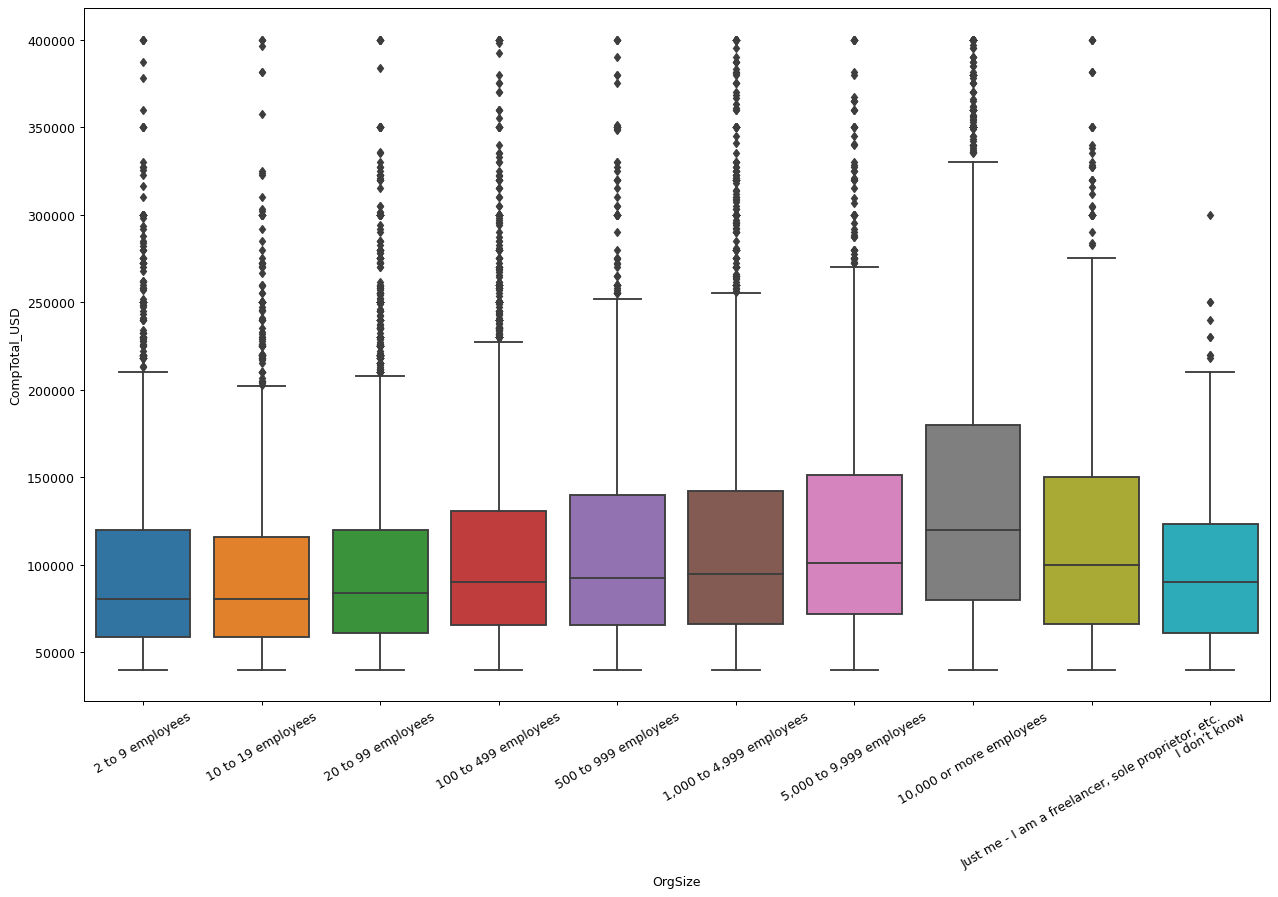

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(17, 10), dpi=90)
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 400000)]
g = sns.boxplot(x = 'OrgSize',y = 'CompTotal_USD', data = temp2, 
                order = ['2 to 9 employees','10 to 19 employees','20 to 99 employees','100 to 499 employees',
                         '500 to 999 employees', '1,000 to 4,999 employees', '5,000 to 9,999 employees', 
                         '10,000 or more employees', 'Just me - I am a freelancer, sole proprietor, etc.',
                        'I don’t know'])
plt.xticks(rotation=30)

## Relation between annual compensation and work location

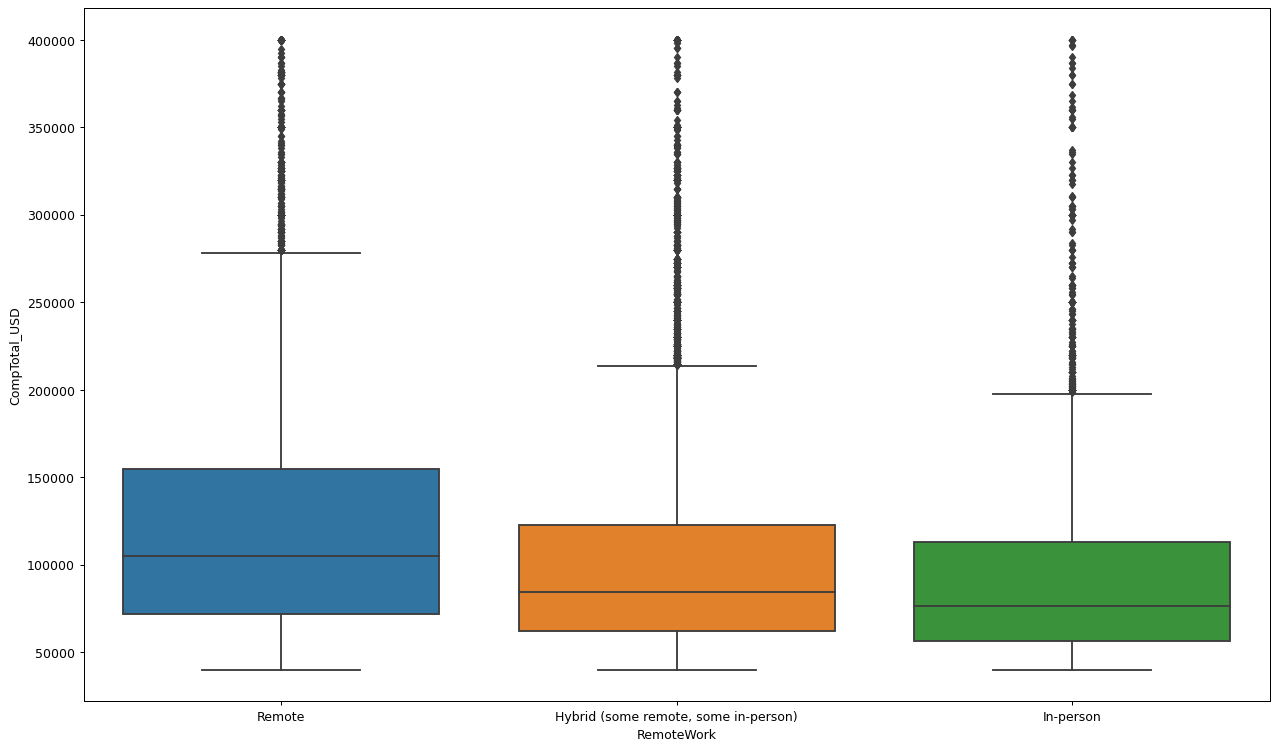

In [51]:
plt.figure(figsize=(17, 10), dpi=90)
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 400000)]
g = sns.boxplot(x = 'RemoteWork',y = 'CompTotal_USD', data = temp2)

## Work location counts

<AxesSubplot:xlabel='RemoteWork', ylabel='count'>

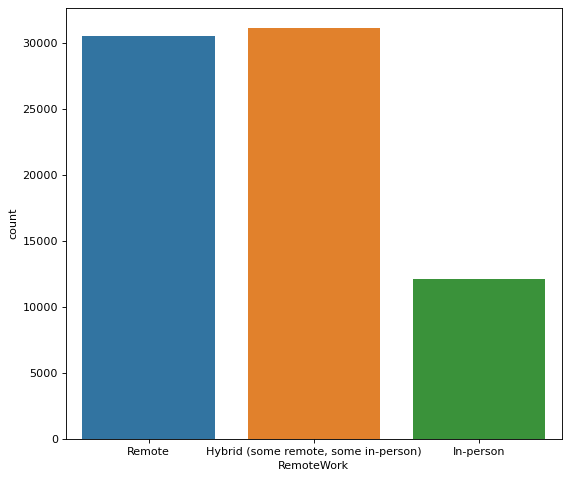

In [52]:
plt.figure(figsize=(8, 7), dpi=80)
sns.countplot(x = 'RemoteWork', data = df2)

## Relation between professional coding experience and annual compensation

In [53]:
df2['YearsCodePro'].unique()

array([nan, '9', '23', '7', '4', '21', '3', '15', 'Less than 1 year',
       '10', '2', '6', '14', '5', '19', '13', '16', '28', '1', '30', '11',
       '8', '25', '32', '24', '40', '17', '45', '29', '12', '31', '20',
       '18', '50', '27', '43', '22', '26', '38', '33', '44', '35', '34',
       '37', '42', '41', 'More than 50 years', '47', '36', '39', '48',
       '46', '49'], dtype=object)

In [54]:
def YearsCodeProCat(x):
    if len(str(x)) <= 2:
        if 1<=int(x)<=3:
            return '1 to 3'
        elif 4<=int(x)<=6:
            return '4 to 6'
        elif 7<=int(x)<=10:
            return '7 to 10'
        elif 11<=int(x)<=20:
            return '11 to 20'
        elif 21<=int(x)<=30:
            return '21 to 30'
        elif 31<=int(x)<=40:
            return '31 to 40'
        elif 41<=int(x)<=50:
            return '41 to 50'
    else:
        return x
df2['YearsCodePro_CAT'] = df2['YearsCodePro'].apply(lambda row: YearsCodeProCat(row))
df2['YearsCodePro_CAT'].unique()

array([nan, '7 to 10', '21 to 30', '4 to 6', '1 to 3', '11 to 20',
       'Less than 1 year', '31 to 40', '41 to 50', 'More than 50 years'],
      dtype=object)

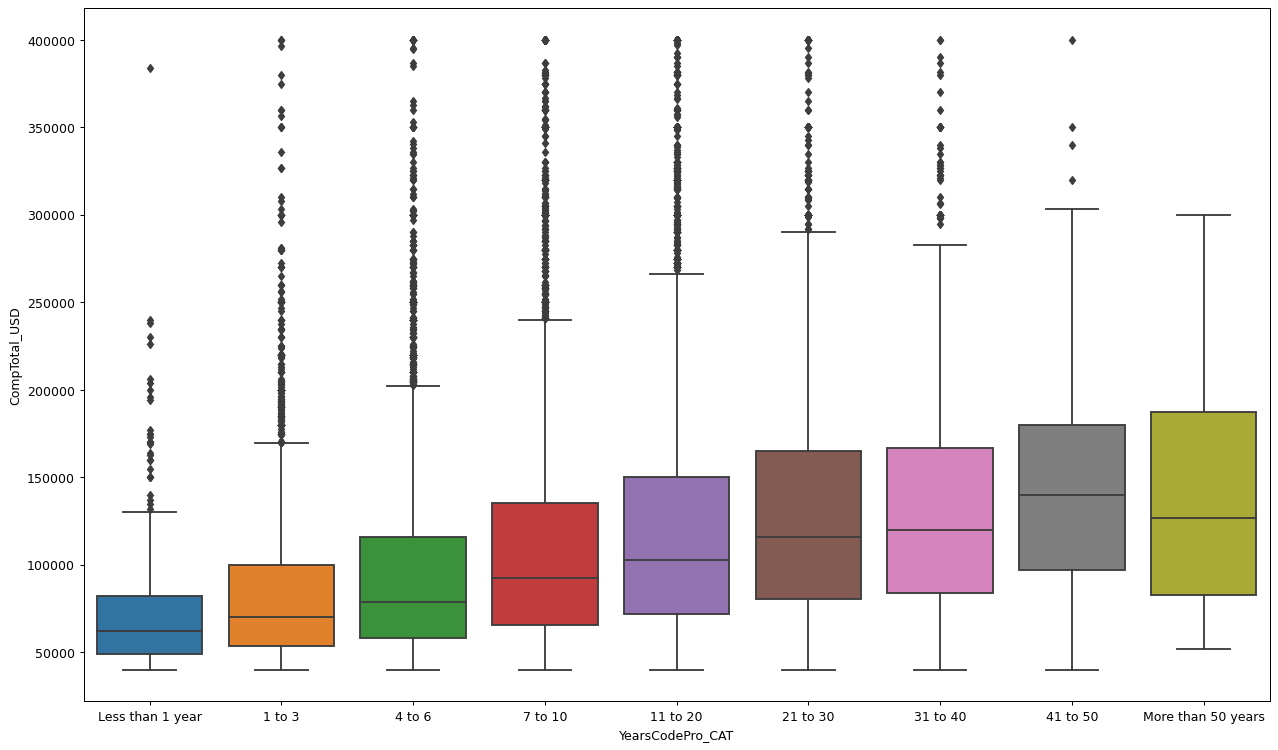

In [55]:
plt.figure(figsize=(17, 10), dpi=90)
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 400000)]
g = sns.boxplot(x = 'YearsCodePro_CAT',y = 'CompTotal_USD', data = temp2, 
                order = ['Less than 1 year','1 to 3','4 to 6','7 to 10','11 to 20','21 to 30','31 to 40','41 to 50',
                         'More than 50 years'])

## Relation between non-professional coding experience and annual compensation

In [56]:
df2['YearsCode'].unique()

array([nan, '18', '27', '12', '6', '21', '4', '5', '20', '14', '10', '15',
       '11', '3', '24', '8', '13', 'Less than 1 year', '16', '33', '22',
       '30', '32', '7', '35', '28', '40', '17', '29', '19',
       'More than 50 years', '9', '38', '26', '34', '25', '2', '45', '23',
       '31', '43', '1', '48', '41', '50', '39', '42', '37', '36', '44',
       '46', '49', '47'], dtype=object)

In [57]:
def YearsCodeCat(x):
    if len(str(x)) <= 2:
        if 1<=int(x)<=3:
            return '1 to 3'
        elif 4<=int(x)<=6:
            return '4 to 6'
        elif 7<=int(x)<=10:
            return '7 to 10'
        elif 11<=int(x)<=20:
            return '11 to 20'
        elif 21<=int(x)<=30:
            return '21 to 30'
        elif 31<=int(x)<=40:
            return '31 to 40'
        elif 41<=int(x)<=50:
            return '41 to 50'
    else:
        return x
df2['YearsCode_CAT'] = df2['YearsCode'].apply(lambda row: YearsCodeCat(row))
df2['YearsCode_CAT'].unique()

array([nan, '11 to 20', '21 to 30', '4 to 6', '7 to 10', '1 to 3',
       'Less than 1 year', '31 to 40', 'More than 50 years', '41 to 50'],
      dtype=object)

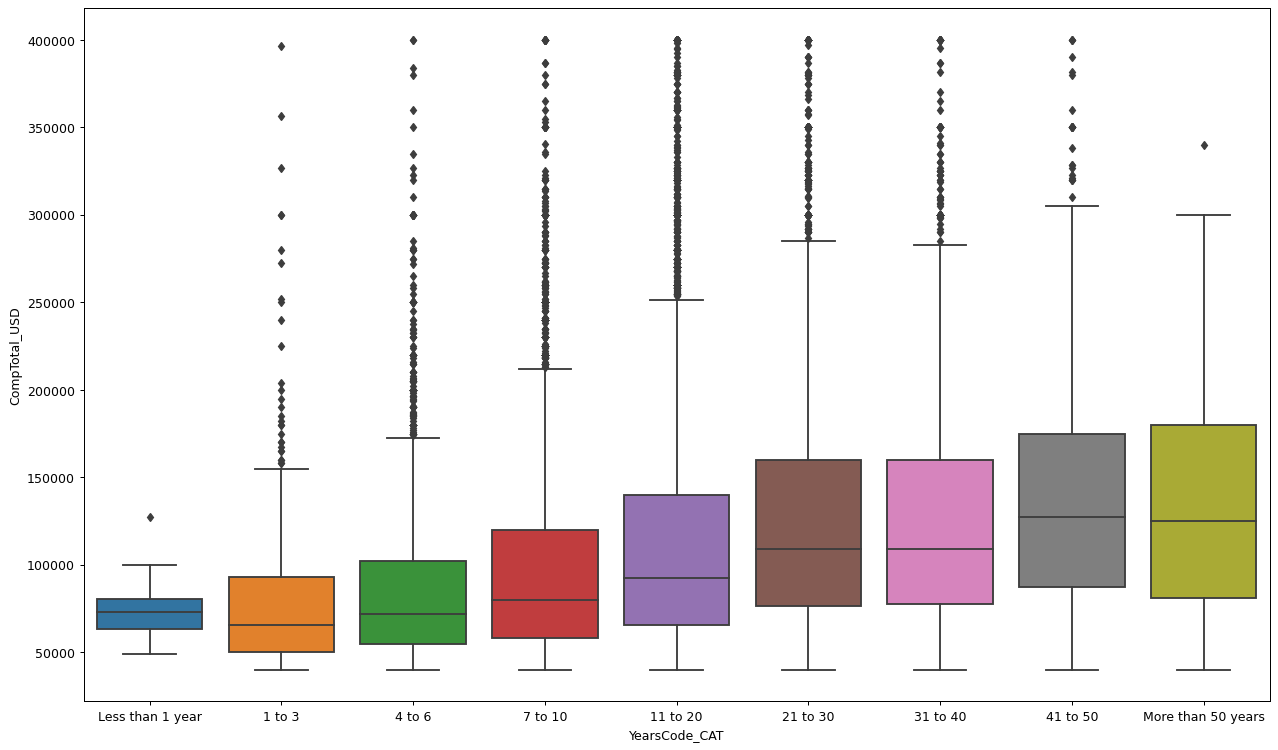

In [58]:
plt.figure(figsize=(17, 10), dpi=90)
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 400000)]
g = sns.boxplot(x = 'YearsCode_CAT',y = 'CompTotal_USD', data = temp2, 
                order = ['Less than 1 year','1 to 3','4 to 6','7 to 10','11 to 20','21 to 30','31 to 40','41 to 50',
                         'More than 50 years'])

## Relation between employment and professional coding experience

In [59]:
def YearsCodeProNum(x):
    if len(str(x)) <= 2:
        return int(x)
    elif str(x) == 'Less than 1 year':
        return 1
    elif str(x) == 'More than 50 years':
        return 50
    else:
        return x
    
df2['YearsCodePro_NUM'] = df2['YearsCodePro'].apply(lambda row: YearsCodeProNum(row))
df2['YearsCodePro_NUM'].unique()

array([nan,  9., 23.,  7.,  4., 21.,  3., 15.,  1., 10.,  2.,  6., 14.,
        5., 19., 13., 16., 28., 30., 11.,  8., 25., 32., 24., 40., 17.,
       45., 29., 12., 31., 20., 18., 50., 27., 43., 22., 26., 38., 33.,
       44., 35., 34., 37., 42., 41., 47., 36., 39., 48., 46., 49.])

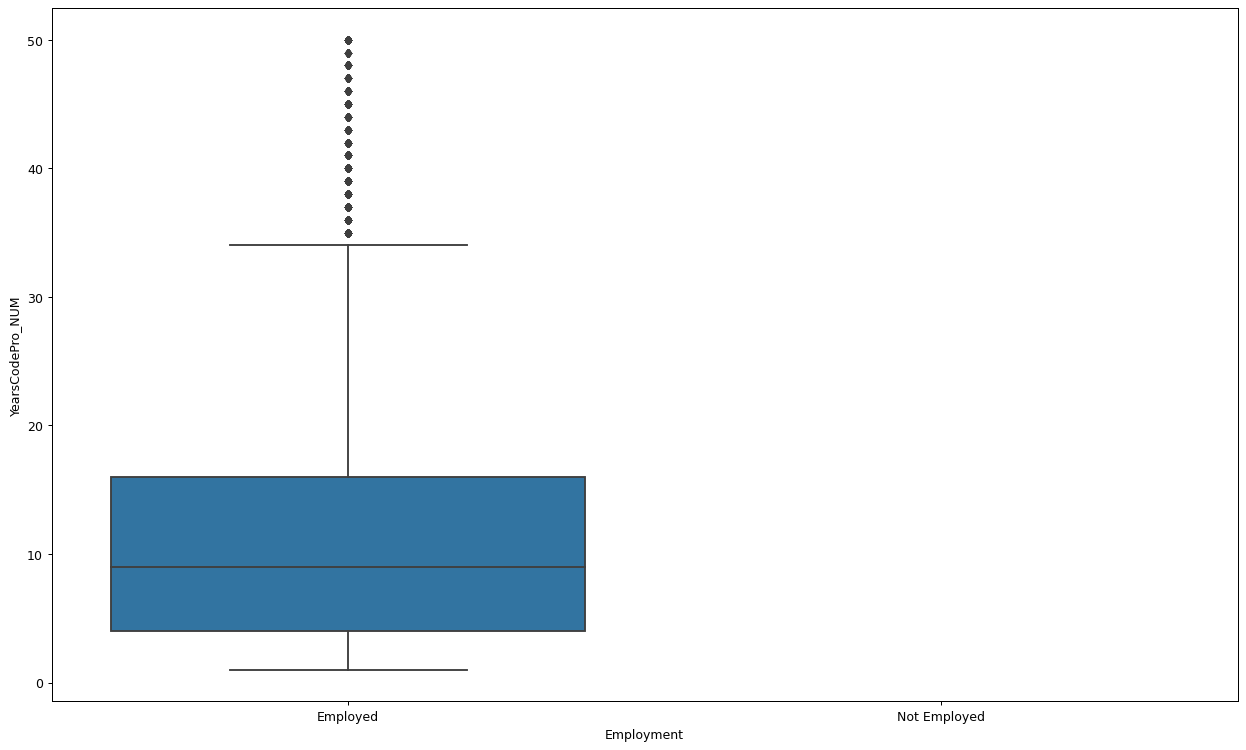

In [60]:
plt.figure(figsize=(17, 10), dpi=90)
g = sns.boxplot(x = 'Employment',y = 'YearsCodePro_NUM', data = df2)                

In [61]:
df2[df2['Employment'] == 'Not Employed']['YearsCodePro'].unique()

array([nan], dtype=object)

## Countplot on ways to learn coding

In [62]:
df2['LearnCode_Online Courses or Certification']

0        0
1        1
2        0
3        0
4        1
        ..
89179    1
89180    1
89181    1
89182    1
89183    1
Name: LearnCode_Online Courses or Certification, Length: 89184, dtype: int64

In [63]:
LearnCode = []
LearnCode_d = {}
for i in df2.columns:
    if 'LearnCode_' in i:
        LearnCode.append(i)
count = 0
for i in LearnCode:
    count = len(df2[df2[i] == 1])
    LearnCode_d[i.split('_')[1]] = count
LearnCode_d    

{'Books / Physical media': 45406,
 'Coding Bootcamp': 8602,
 'Colleague': 20523,
 'Friend or family member': 9936,
 'Hackathons (virtual or in-person)': 7033,
 'On the job training': 40380,
 'Online Courses or Certification': 43201,
 'Other (please specify):': 5451,
 'Other online resources (e.g., videos, blogs, forum)': 70244,
 'School (i.e., University, College, etc)': 43957}

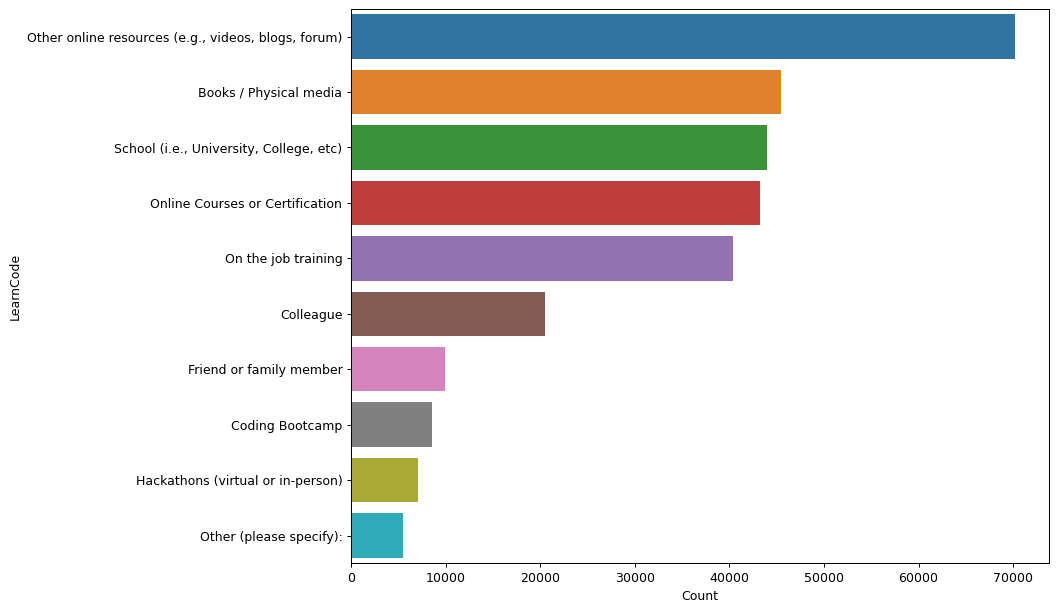

In [64]:
plt.figure(figsize=(10, 8), dpi=90)
pd_df = pd.DataFrame(list(LearnCode_d.items()))
pd_df.columns =["LearnCode", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='LearnCode', data = pd_df, order = pd_df['LearnCode'])
#plt.bar(*zip(*LearnCode_d.items()))
plt.show()

## Countplot on learning to code online 

In [65]:
LearnCodeOnline = []
LearnCodeOnline_d = {}
for i in df2.columns:
    if 'LearnCodeOnline_' in i:
        LearnCodeOnline.append(i)
count = 0
for i in LearnCodeOnline:
    count = len(df2[df2[i] == 1])
    LearnCodeOnline_d[i.split('_')[1]] = count
LearnCodeOnline_d    

{'Auditory material (e.g., podcasts)': 5571,
 'Blogs with tips and tricks': 53745,
 'Books': 30432,
 'Certification videos': 9326,
 'Click to write Choice 20': 29780,
 'Formal documentation provided by the owner of the tech': 63329,
 'How-to videos': 42149,
 'Interactive tutorial': 18242,
 'Online challenges (e.g., daily or weekly coding challenges)': 15544,
 'Other (Please specify):': 2280,
 'Programming Games': 4131,
 'Recorded coding sessions': 19690,
 'Stack Overflow': 57861,
 'Video-based Online Courses': 34629,
 'Written Tutorials': 42012,
 'Written-based Online Courses': 25309}

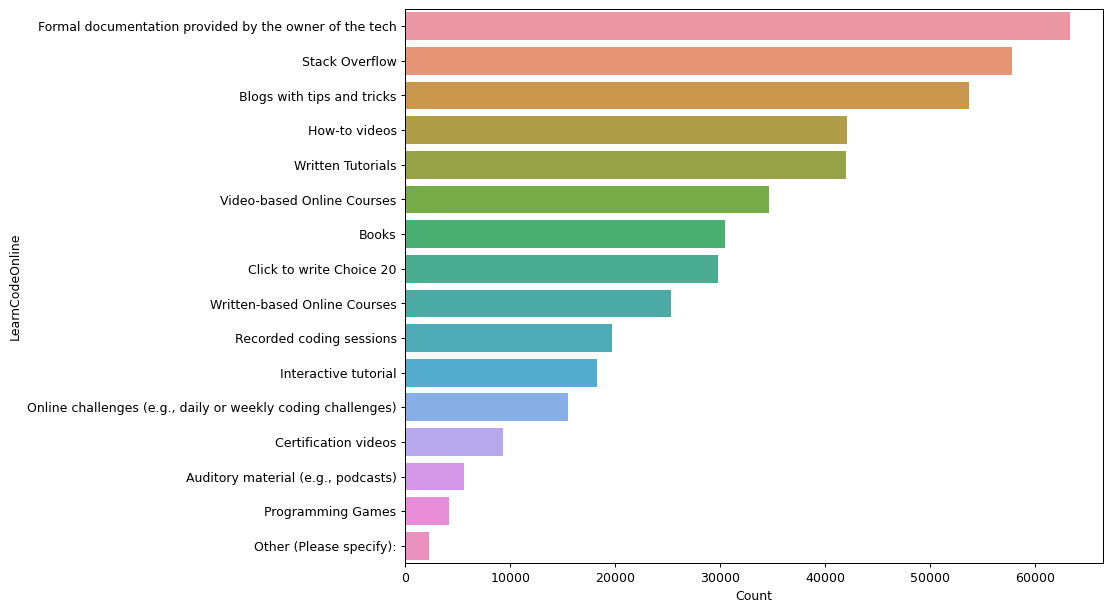

In [66]:
plt.figure(figsize=(10, 8), dpi=90)
pd_df = pd.DataFrame(list(LearnCodeOnline_d.items()))
pd_df.columns =["LearnCodeOnline", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='LearnCodeOnline', data = pd_df, order = pd_df['LearnCodeOnline'])
#plt.bar(*zip(*LearnCode_d.items()))
plt.show()

## Countplot on learning to code by gaining a course certificate

In [67]:
LearnCodeCert = []
LearnCodeCert_d = {}
for i in df2.columns:
    if 'LearnCodeCoursesCert_' in i:
        LearnCodeCert.append(i)
count = 0
for i in LearnCodeCert:
    count = len(df2[df2[i] == 1])
    LearnCodeCert_d[i.split('_')[1]] = count
LearnCodeCert_d    

{'Codecademy': 9015,
 'Coursera': 12836,
 'Other': 7811,
 'Pluralsight': 8463,
 'Skillsoft': 754,
 'Udacity': 3992,
 'Udemy': 24296,
 'edX': 5536}

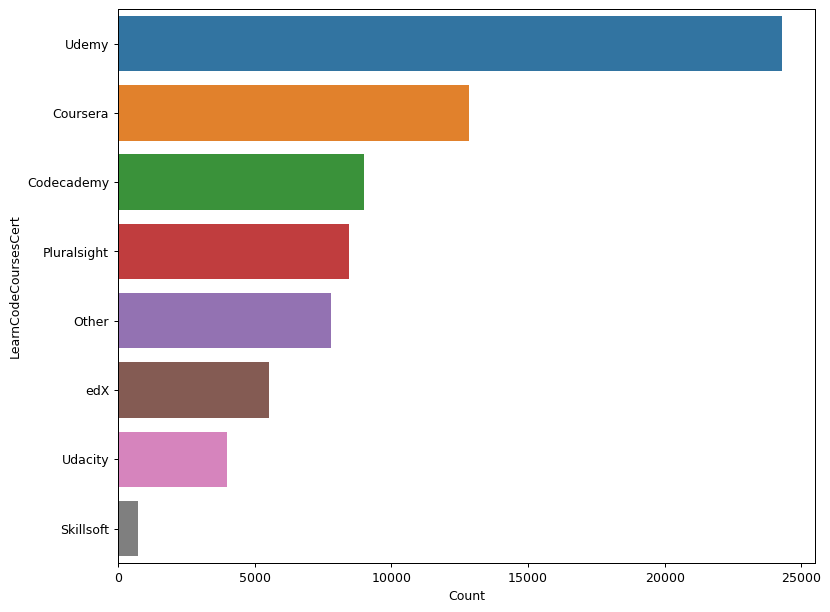

In [68]:
plt.figure(figsize=(10, 8), dpi=90)
pd_df = pd.DataFrame(list(LearnCodeCert_d.items()))
pd_df.columns =["LearnCodeCoursesCert", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='LearnCodeCoursesCert', data = pd_df, order = pd_df['LearnCodeCoursesCert'])
#plt.bar(*zip(*LearnCode_d.items()))
plt.show()

## Relation between education level and employment

[Text(0, 0, 'Bachelor’s degree'),
 Text(1, 0, 'Some college/university'),
 Text(2, 0, 'Master’s degree'),
 Text(3, 0, 'Primary/elementary school'),
 Text(4, 0, 'Professional degree(ph.D)'),
 Text(5, 0, 'Associate degree'),
 Text(6, 0, 'Secondary school'),
 Text(7, 0, 'Something else')]

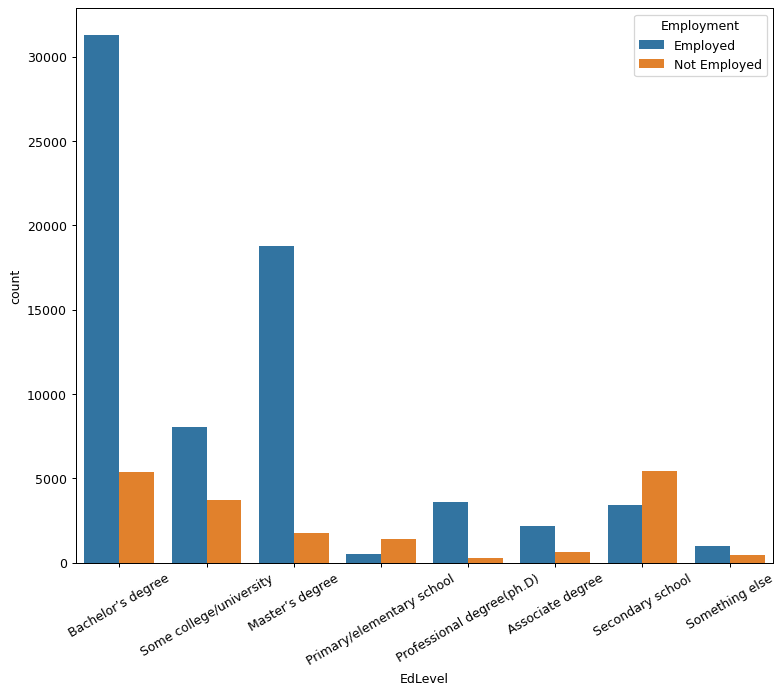

In [69]:
plt.figure(figsize=(10, 8), dpi=90)
g = sns.countplot(x='EdLevel', hue = 'Employment',data = df2)
plt.xticks(rotation=30)
g.set_xticklabels(['Bachelor’s degree','Some college/university','Master’s degree','Primary/elementary school',
                   'Professional degree(ph.D)','Associate degree','Secondary school','Something else'])

## Countplot of coding languages used by developers

In [70]:
languages = []
languages_d = {}
for i in df2.columns:
    if 'LanguageHaveWorkedWith_' in i:
        languages.append(i)
count = 0
for i in languages:
    count = len(df2[df2[i] == 1])
    languages_d[i.split('_')[1]] = count
languages_d    

{'APL': 225,
 'Ada': 677,
 'Apex': 579,
 'Assembly': 4753,
 'Bash/Shell (all shells)': 28351,
 'C': 16940,
 'C#': 24193,
 'C++': 19634,
 'Clojure': 1105,
 'Cobol': 576,
 'Crystal': 389,
 'Dart': 5273,
 'Delphi': 2831,
 'Elixir': 2028,
 'Erlang': 868,
 'F#': 849,
 'Flow': 214,
 'Fortran': 833,
 'GDScript': 1495,
 'Go': 11592,
 'Groovy': 2976,
 'HTML/CSS': 46396,
 'Haskell': 1829,
 'Java': 26757,
 'JavaScript': 55711,
 'Julia': 1010,
 'Kotlin': 7935,
 'Lisp': 1342,
 'Lua': 5336,
 'MATLAB': 3339,
 'Nim': 331,
 'OCaml': 614,
 'Objective-C': 2019,
 'PHP': 16274,
 'Perl': 2151,
 'PowerShell': 11902,
 'Prolog': 776,
 'Python': 43158,
 'R': 3702,
 'Raku': 156,
 'Ruby': 5454,
 'Rust': 11427,
 'SAS': 427,
 'SQL': 42623,
 'Scala': 2422,
 'Solidity': 1168,
 'Swift': 4072,
 'TypeScript': 34041,
 'VBA': 3107,
 'Visual Basic (.Net)': 3568,
 'Zig': 729}

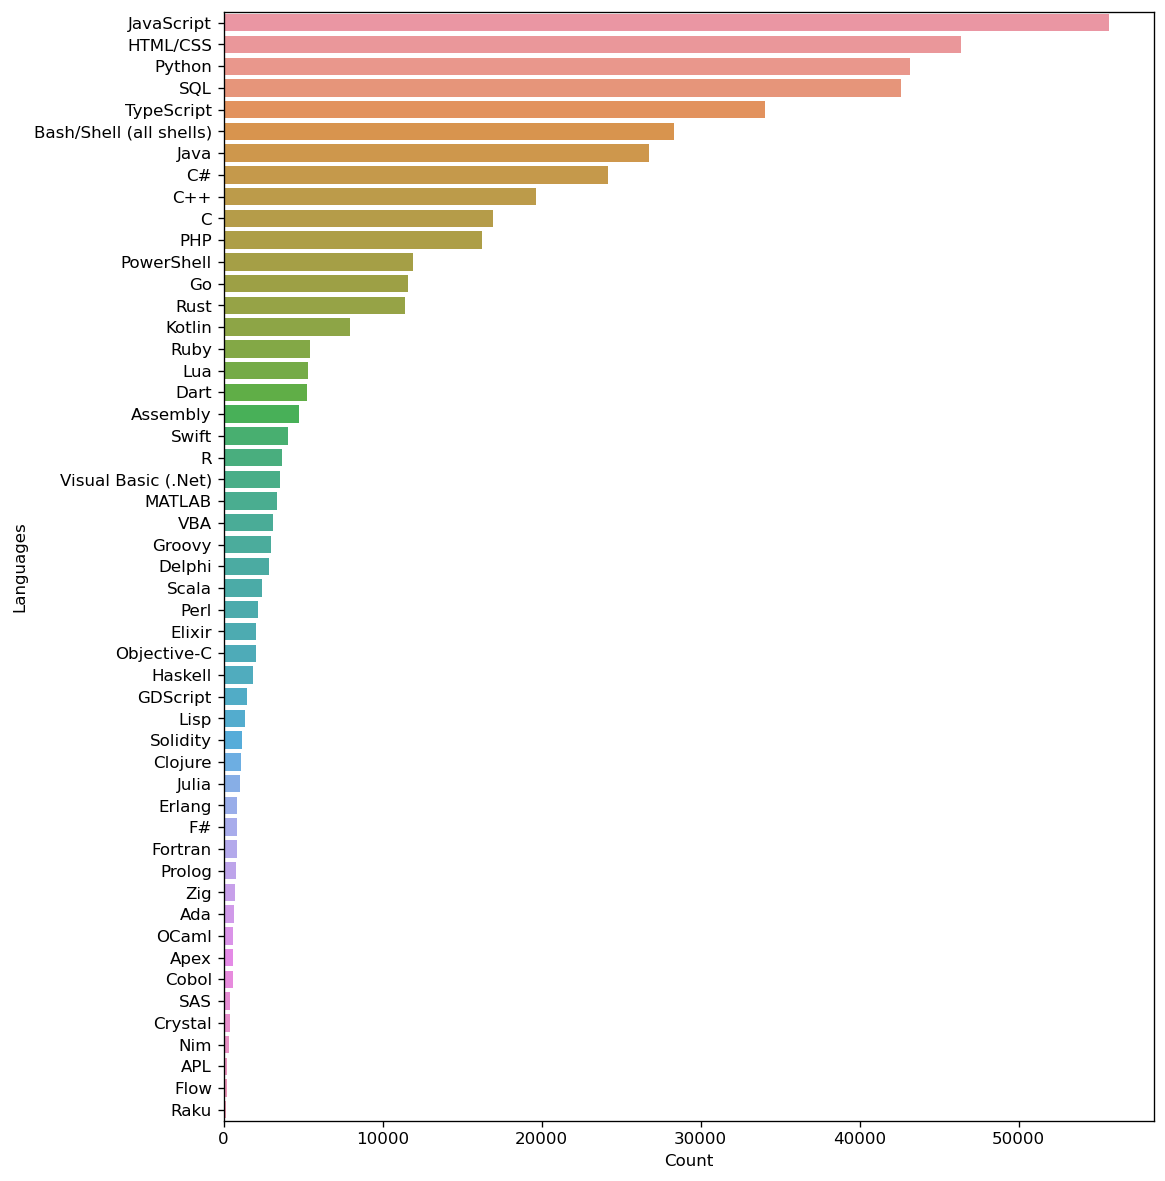

In [71]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(languages_d.items()))
pd_df.columns =["Languages", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='Languages', data = pd_df, order = pd_df['Languages'])
plt.show()

## Countplot of databases used by developers

In [72]:
databases = []
databases_d = {}
for i in df2.columns:
    if 'DatabaseHaveWorkedWith_' in i:
        databases.append(i)
count = 0
for i in databases:
    count = len(df2[df2[i] == 1])
    databases_d[i.split('_')[1]] = count
databases_d    

{'BigQuery': 3456,
 'Cassandra': 1927,
 'Clickhouse': 849,
 'Cloud Firestore': 4901,
 'Cockroachdb': 795,
 'Cosmos DB': 2672,
 'Couch DB': 887,
 'Couchbase': 598,
 'Datomic': 244,
 'DuckDB': 469,
 'Dynamodb': 6798,
 'Elasticsearch': 10263,
 'Firebase Realtime Database': 4939,
 'Firebird': 1152,
 'H2': 2808,
 'IBM DB2': 1414,
 'InfluxDB': 2091,
 'MariaDB': 13495,
 'Microsoft Access': 3257,
 'Microsoft SQL Server': 19506,
 'MongoDB': 19556,
 'MySQL': 31489,
 'Neo4J': 1432,
 'Oracle': 7507,
 'PostgreSQL': 34909,
 'RavenDB': 227,
 'Redis': 15639,
 'SQLite': 23678,
 'Snowflake': 1820,
 'Solr': 1189,
 'Supabase': 2122,
 'TiDB': 157}

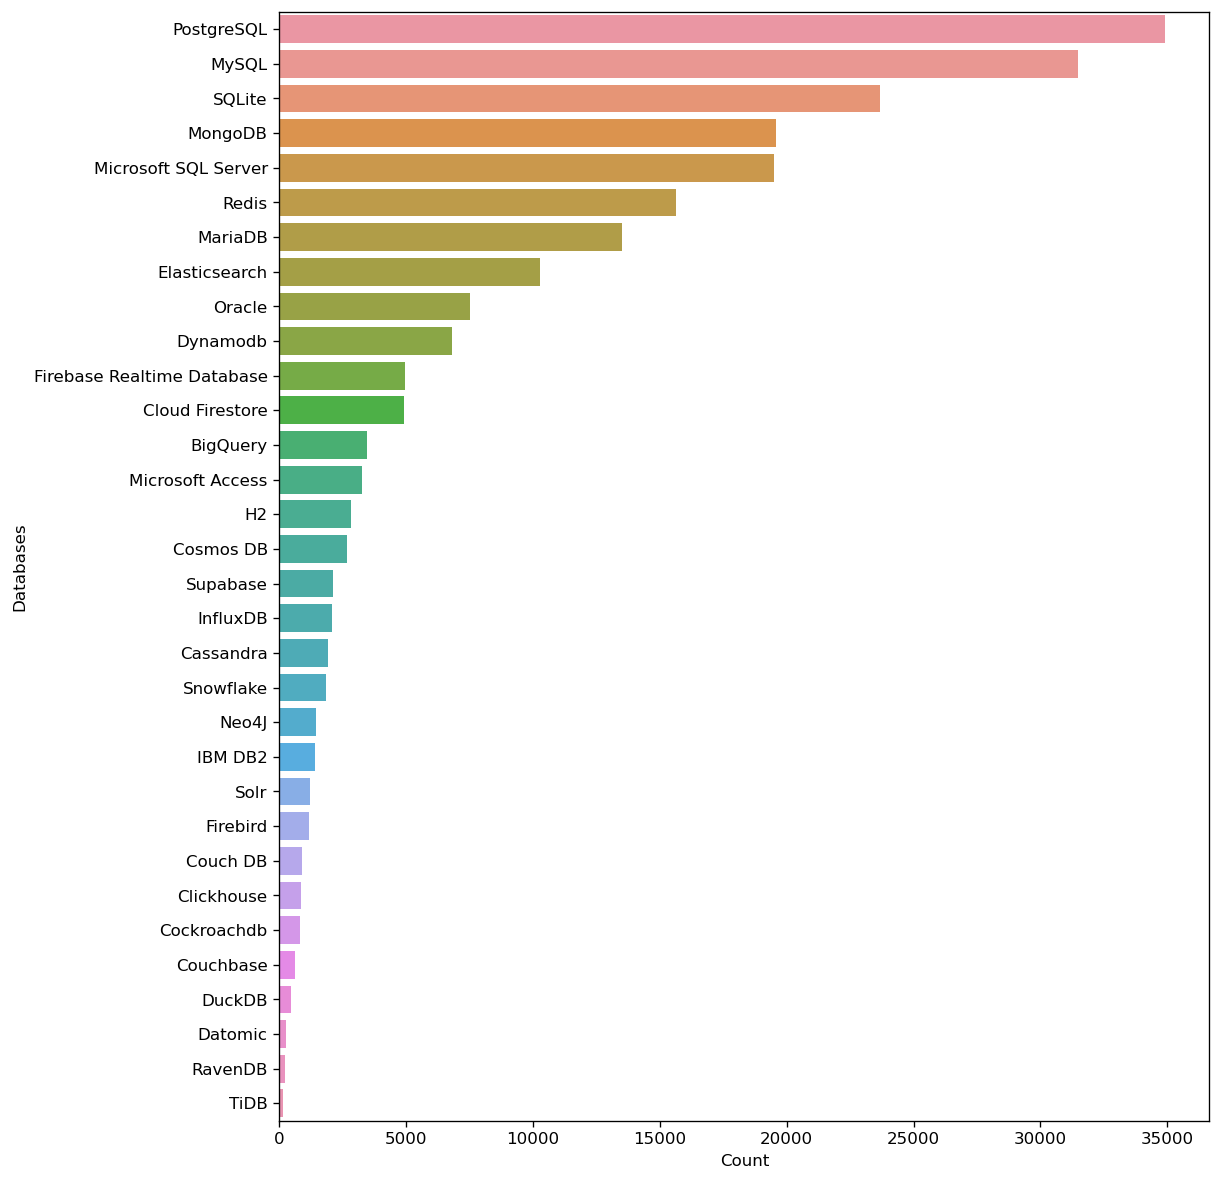

In [73]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(databases_d.items()))
pd_df.columns =["Databases", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='Databases', data = pd_df, order = pd_df['Databases'])
plt.show()

## Countplot of cloud platforms used by developers

In [74]:
platforms = []
platforms_d = {}
for i in df2.columns:
    if 'PlatformHaveWorkedWith_' in i:
        platforms.append(i)
count = 0
for i in platforms:
    count = len(df2[df2[i] == 1])
    platforms_d[i.split('_')[1]] = count
platforms_d    

{'Amazon Web Services (AWS)': 33818,
 'Cloudflare': 10599,
 'Colocation': 497,
 'Digital Ocean': 9299,
 'Firebase': 10761,
 'Fly.io': 1649,
 'Google Cloud': 16592,
 'Heroku': 8358,
 'Hetzner': 3069,
 'IBM Cloud Or Watson': 801,
 'Linode, now Akamai': 2755,
 'Managed Hosting': 2379,
 'Microsoft Azure': 18105,
 'Netlify': 6228,
 'OVH': 2378,
 'OpenShift': 1671,
 'OpenStack': 1076,
 'Oracle Cloud Infrastructure (OCI)': 1810,
 'Render': 1287,
 'Scaleway': 628,
 'VMware': 4964,
 'Vercel': 7431,
 'Vultr': 1357}

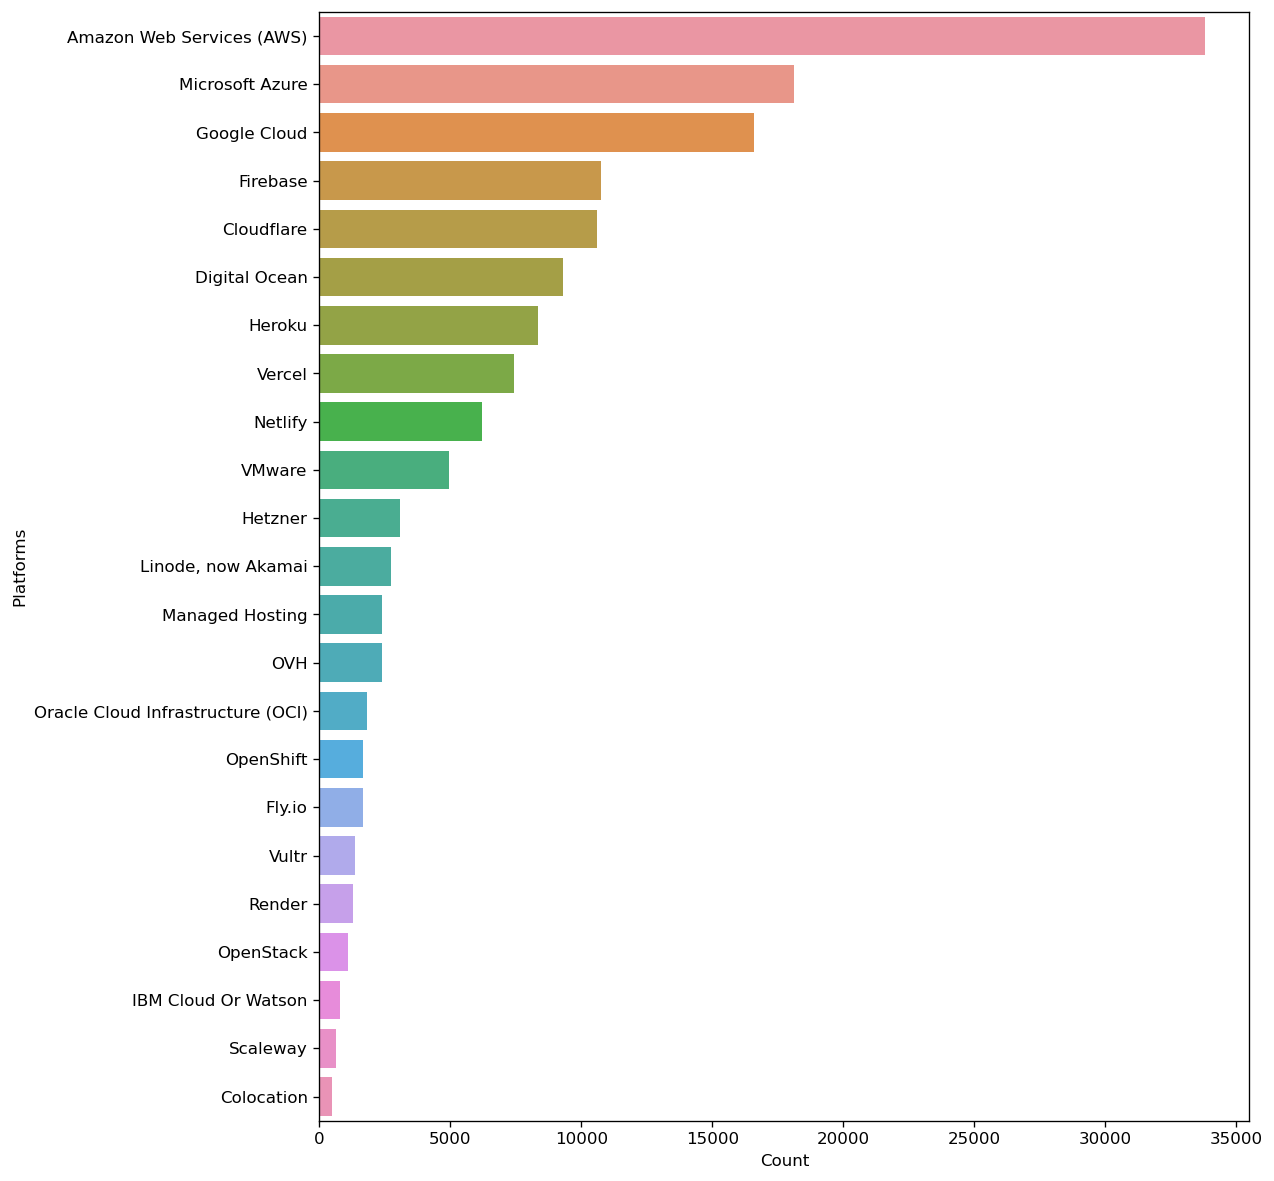

In [75]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(platforms_d.items()))
pd_df.columns =["Platforms", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='Platforms', data = pd_df, order = pd_df['Platforms'])
plt.show()

## Countplot of webframes used by developers

In [76]:
webframes = []
webframes_d = {}
for i in df2.columns:
    if 'WebframeHaveWorkedWith_' in i:
        webframes.append(i)
count = 0
for i in webframes:
    count = len(df2[df2[i] == 1])
    webframes_d[i.split('_')[1]] = count
webframes_d    

{'ASP.NET': 9185,
 'ASP.NET CORE': 11896,
 'Angular': 12537,
 'AngularJS': 5176,
 'Blazor': 3501,
 'CodeIgniter': 1238,
 'Deno': 1697,
 'Django': 8238,
 'Drupal': 1343,
 'Elm': 580,
 'Express': 13843,
 'FastAPI': 5325,
 'Fastify': 1474,
 'Flask': 8734,
 'Gatsby': 1675,
 'Laravel': 5440,
 'Lit': 490,
 'NestJS': 3681,
 'Next.js': 11972,
 'Node.js': 30626,
 'Nuxt.js': 2652,
 'Phoenix': 1468,
 'Play Framework': 545,
 'Qwik': 389,
 'React': 29137,
 'Remix': 912,
 'Ruby on Rails': 3940,
 'Solid.js': 979,
 'Spring Boot': 8583,
 'Svelte': 4753,
 'Symfony': 2301,
 'Vue.js': 11758,
 'WordPress': 9604,
 'jQuery': 15784}

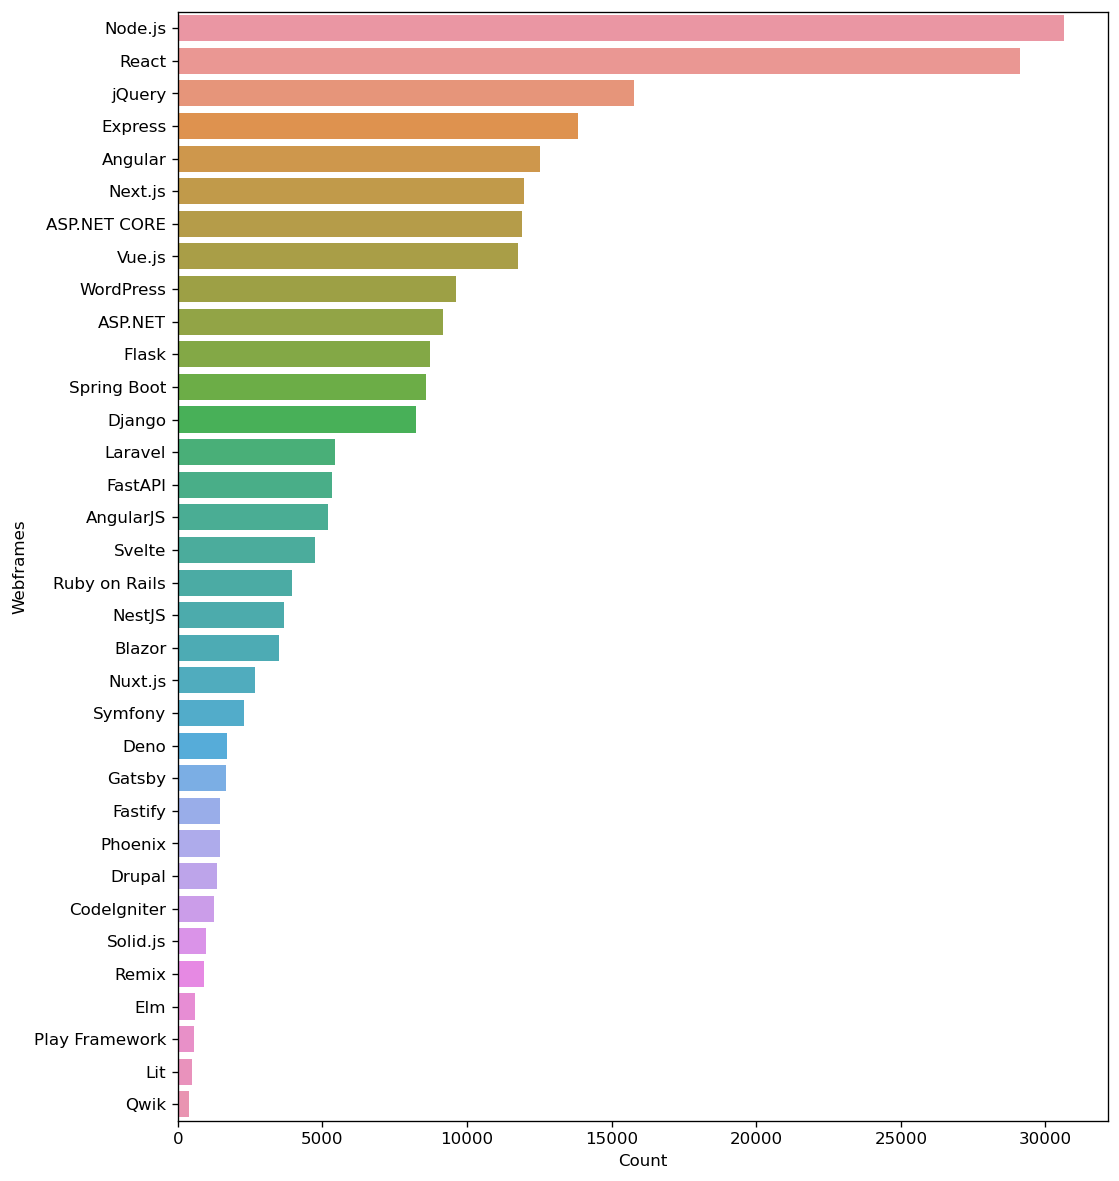

In [77]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(webframes_d.items()))
pd_df.columns =["Webframes", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='Webframes', data = pd_df, order = pd_df['Webframes'])
plt.show()

## Countplot of operating systems used by developers for personal use

In [78]:
opsys_personal = []
opsys_personal_d = {}
for i in df2.columns:
    if 'OpSysPersonal use_' in i:
        opsys_personal.append(i)
count = 0
for i in opsys_personal:
    count = len(df2[df2[i] == 1])
    opsys_personal_d[i.split('_')[1]] = count
opsys_personal_d    

{'AIX': 251,
 'Android': 15343,
 'Arch': 7029,
 'BSD': 839,
 'ChromeOS': 1636,
 'Cygwin': 908,
 'Debian': 7317,
 'Fedora': 3812,
 'Haiku': 176,
 'MacOS': 28407,
 'Other (Please Specify):': 2062,
 'Other Linux-based': 7115,
 'Red Hat': 1864,
 'Solaris': 280,
 'Ubuntu': 23791,
 'Windows': 52086,
 'Windows Subsystem for Linux (WSL)': 14710,
 'iOS': 10237,
 'iPadOS': 4956}

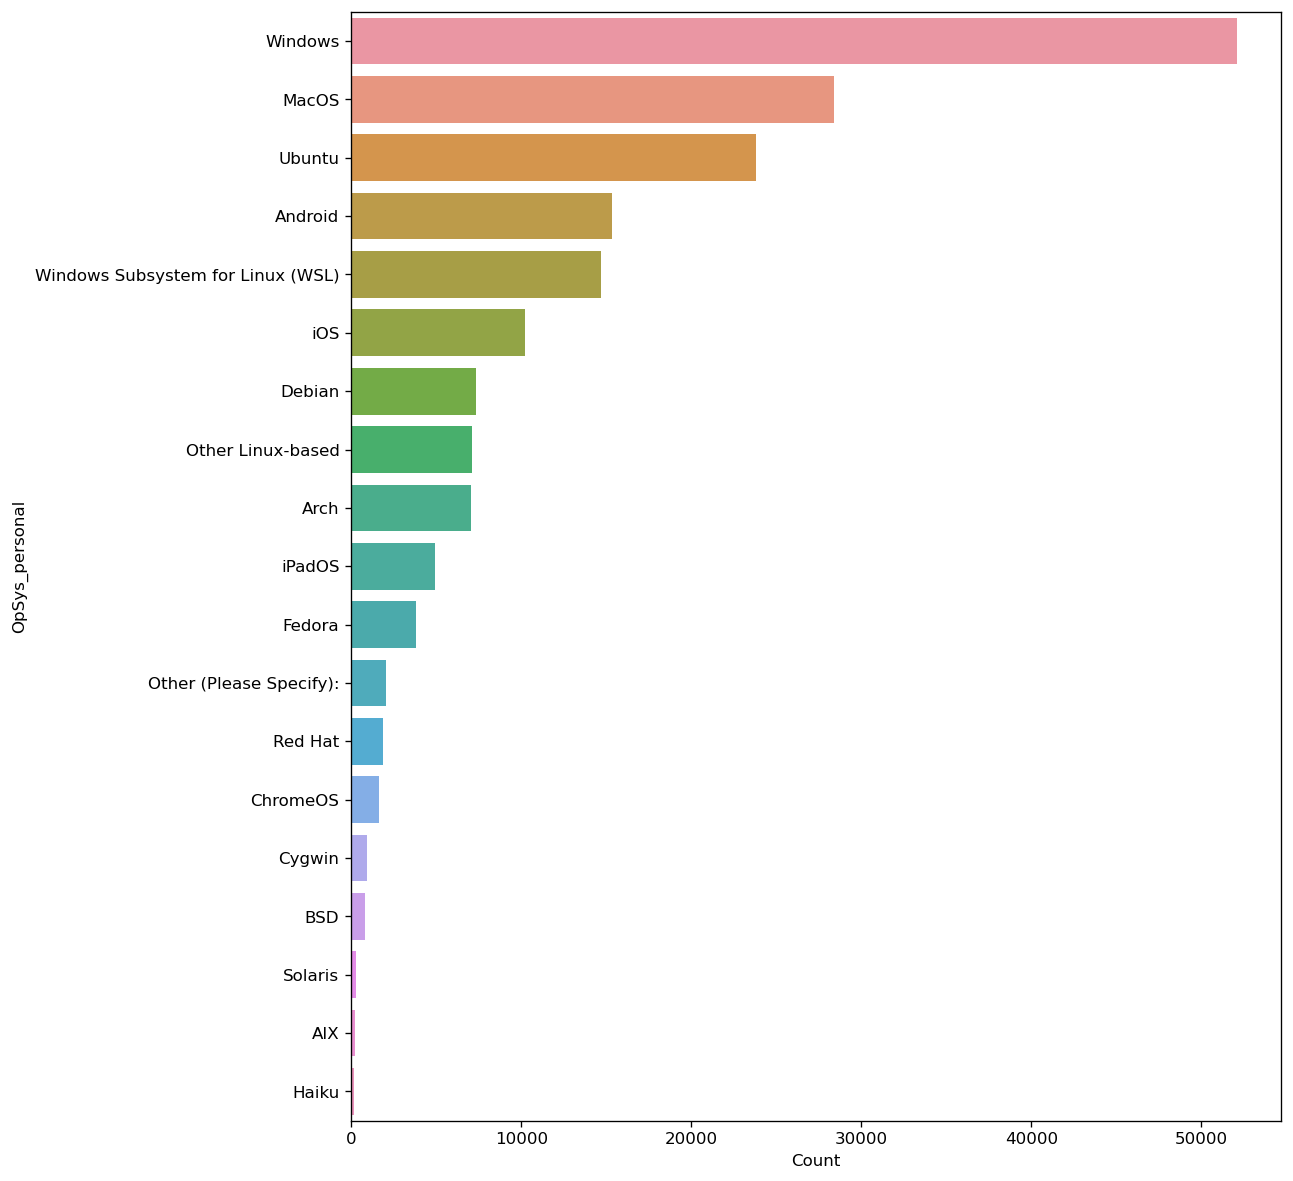

In [79]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(opsys_personal_d.items()))
pd_df.columns =["OpSys_personal", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='OpSys_personal', data = pd_df, order = pd_df['OpSys_personal'])
plt.show()

## Countplot of operating systems used by developers for professional use

In [80]:
opsys_pro = []
opsys_pro_d = {}
for i in df2.columns:
    if 'OpSysProfessional use_' in i:
        opsys_pro.append(i)
count = 0
for i in opsys_pro:
    count = len(df2[df2[i] == 1])
    opsys_pro_d[i.split('_')[1]] = count
opsys_pro_d   

{'AIX': 355,
 'Android': 7175,
 'Arch': 3809,
 'BSD': 517,
 'ChromeOS': 927,
 'Cygwin': 805,
 'Debian': 7059,
 'Fedora': 2662,
 'Haiku': 74,
 'MacOS': 28786,
 'Other (Please Specify):': 1700,
 'Other Linux-based': 6712,
 'Red Hat': 4043,
 'Solaris': 318,
 'Ubuntu': 23281,
 'Windows': 40917,
 'Windows Subsystem for Linux (WSL)': 13674,
 'iOS': 6429,
 'iPadOS': 2418}

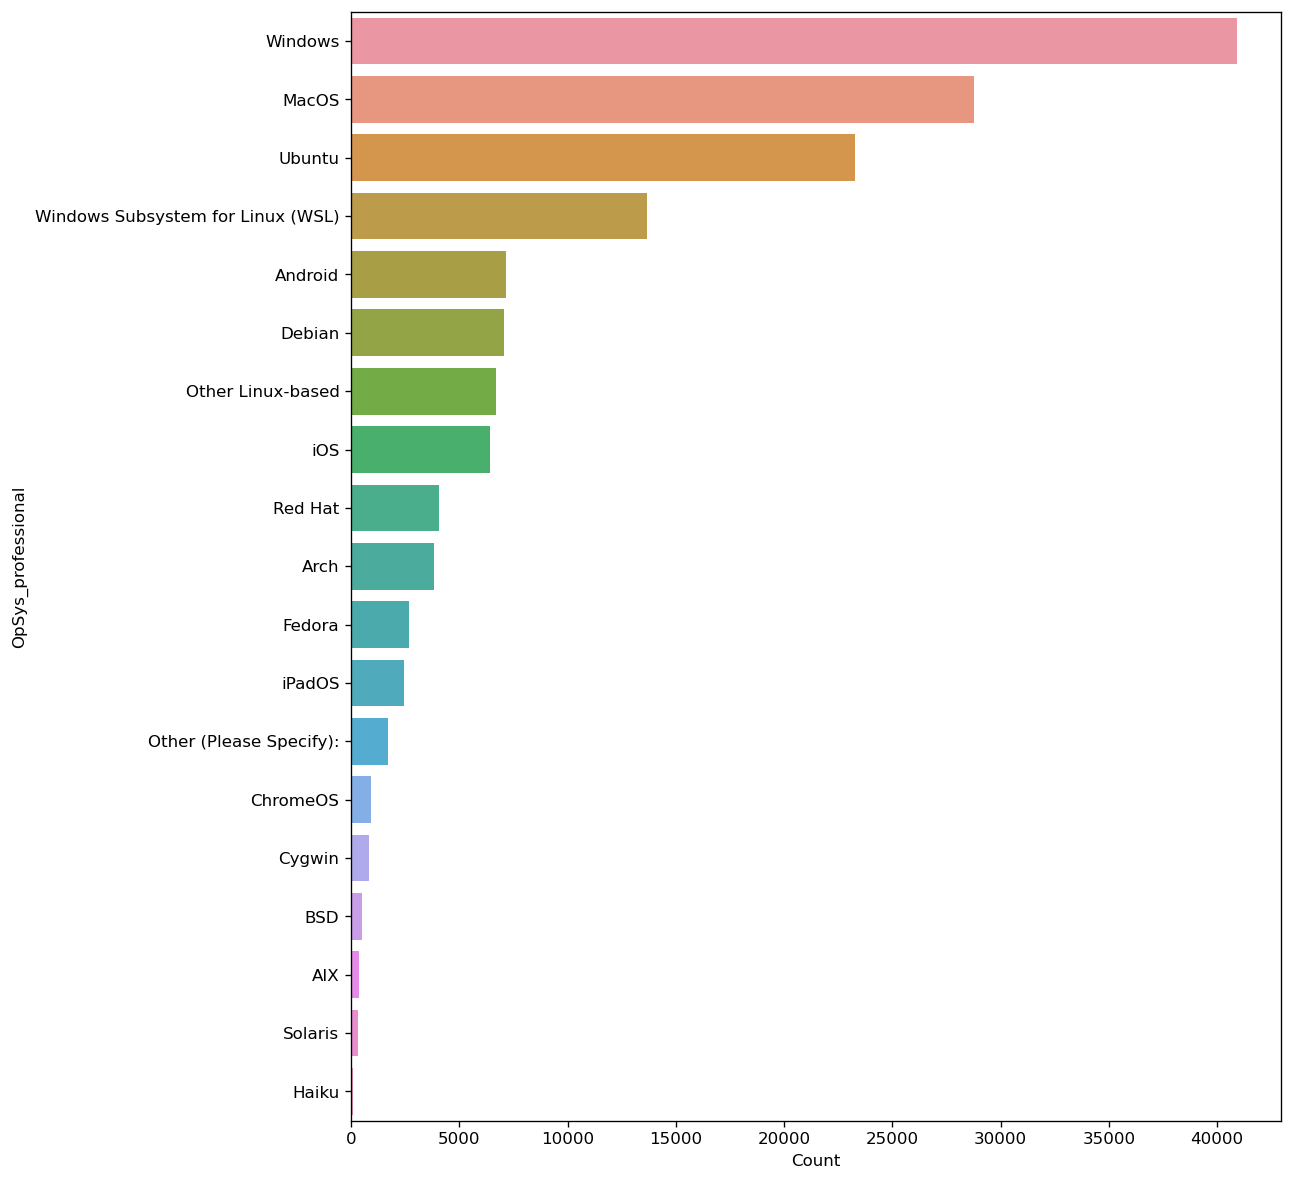

In [81]:
plt.figure(figsize=(10, 12), dpi=120)
pd_df = pd.DataFrame(list(opsys_pro_d.items()))
pd_df.columns =["OpSys_professional", "Count"]
pd_df = pd_df.sort_values('Count',ascending=False).reset_index()
sns.barplot(x = 'Count', y='OpSys_professional', data = pd_df, order = pd_df['OpSys_professional'])
plt.show()

## Countplot on whether developers use AI or not in their work

<AxesSubplot:xlabel='AISelect', ylabel='count'>

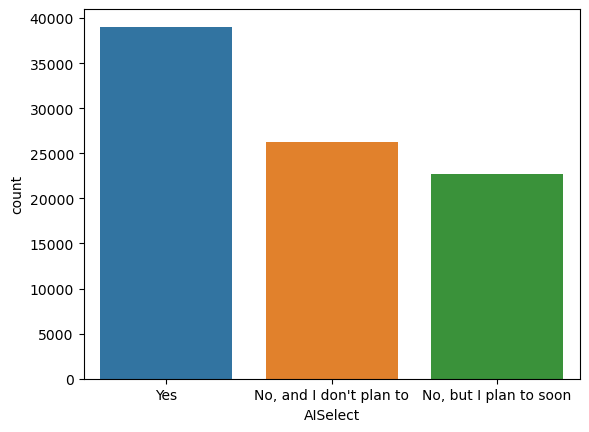

In [82]:
sns.countplot(x='AISelect',data = df2)

## Relation between education level and annual compensation

[Text(0, 0, 'Primary/elementary school'),
 Text(1, 0, 'Secondary school'),
 Text(2, 0, 'Associate degree'),
 Text(3, 0, 'Some college/university'),
 Text(4, 0, 'Bachelor’s degree'),
 Text(5, 0, 'Master’s degree'),
 Text(6, 0, 'Professional degree(ph.D)'),
 Text(7, 0, 'Something else')]

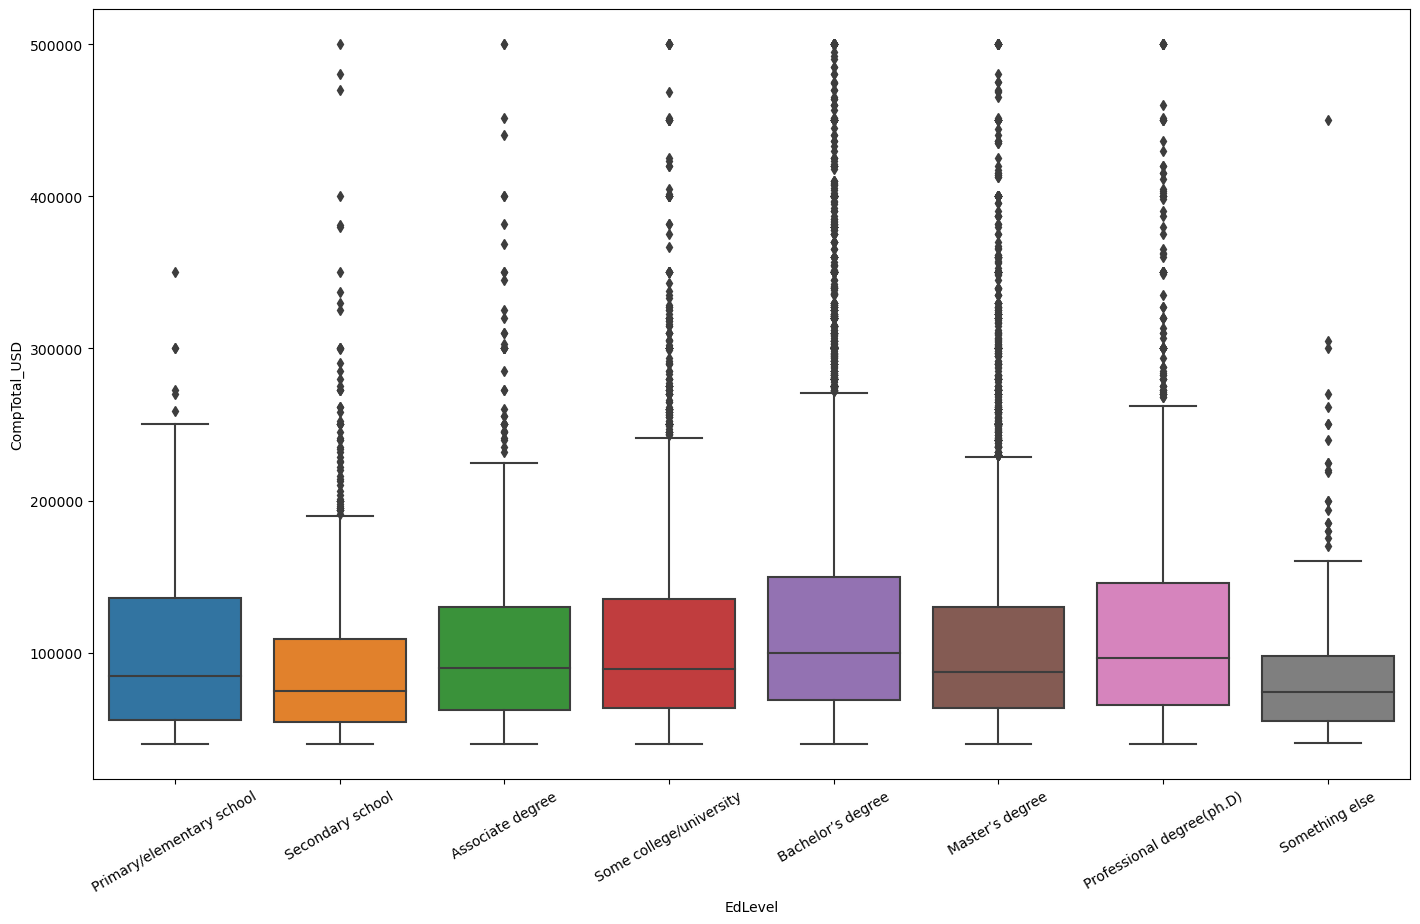

In [83]:
plt.figure(figsize=(17, 10))
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 500000)]
g = sns.boxplot(x = 'EdLevel',y = 'CompTotal_USD', data = temp2, 
                order = ['Primary/elementary school','Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)'
                        ,'Associate degree (A.A., A.S., etc.)','Some college/university study without earning a degree',
                        'Bachelor’s degree (B.A., B.S., B.Eng., etc.)','Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
                        'Professional degree (JD, MD, Ph.D, Ed.D, etc.)','Something else'])
plt.xticks(rotation=30)
g.set_xticklabels(['Primary/elementary school', 'Secondary school','Associate degree', 'Some college/university',
                   'Bachelor’s degree','Master’s degree','Professional degree(ph.D)','Something else'])

In [84]:
df2['EdLevel'].unique()

array([nan, 'Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
       'Some college/university study without earning a degree',
       'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
       'Primary/elementary school',
       'Professional degree (JD, MD, Ph.D, Ed.D, etc.)',
       'Associate degree (A.A., A.S., etc.)',
       'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)',
       'Something else'], dtype=object)

## Relation between Developer type and annual compensation

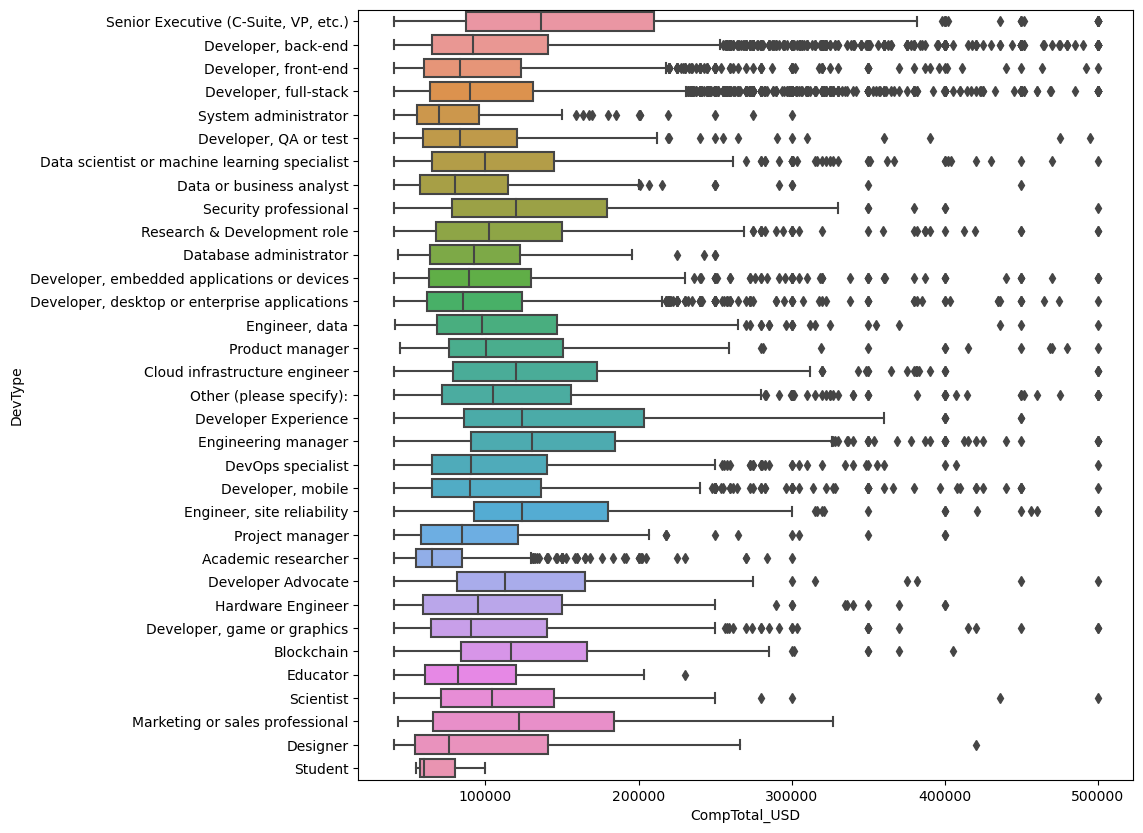

In [85]:
plt.figure(figsize=(10, 10))
temp2 = df2[(df2['CompTotal_USD'] >= 40000) & (df2['CompTotal_USD'] <= 500000)]
g = sns.boxplot(x = 'CompTotal_USD',y = 'DevType', data = temp2)

In [86]:
df2[(df2['Employment'] == 'Not Employed')&(df2['CompTotal'] > 0)][['DevType','CompTotal_USD']]

,DevType,CompTotal_USD


## Countplot of developer types

<AxesSubplot:xlabel='count', ylabel='DevType'>

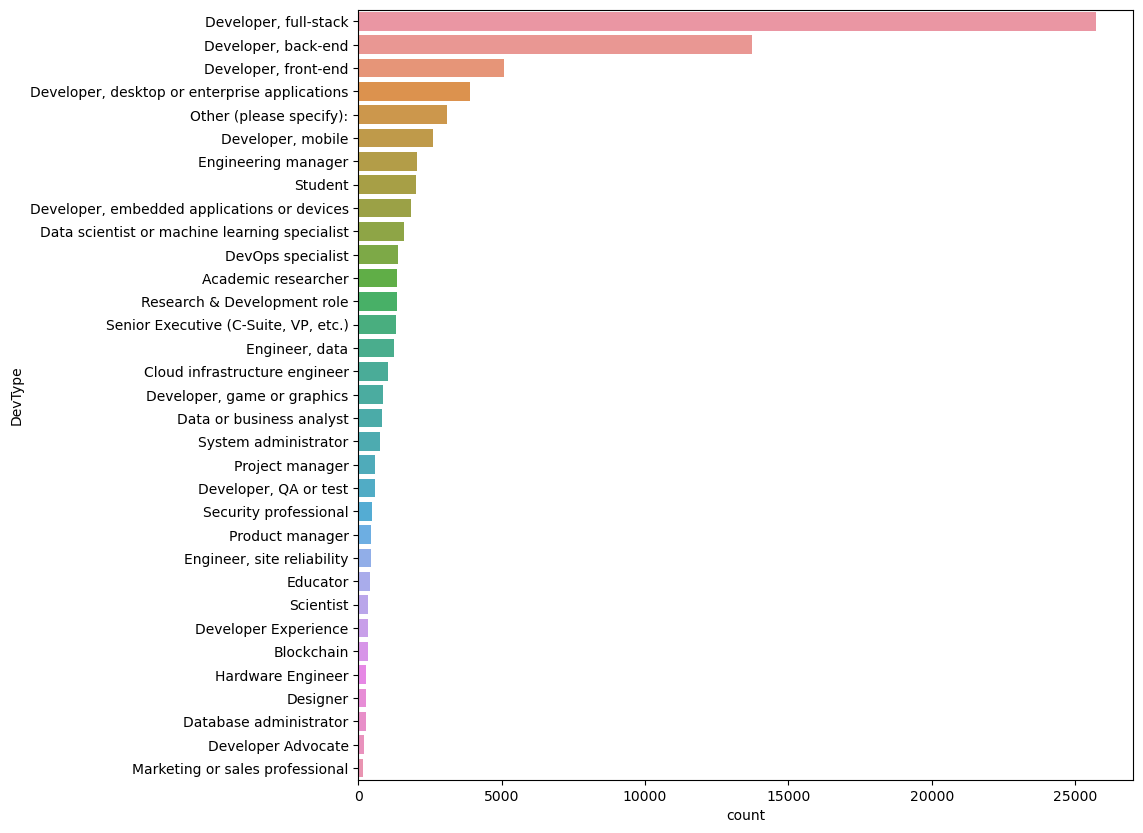

In [87]:
plt.figure(figsize=(10, 10))
sns.countplot(y = 'DevType', data = df2, order = df2['DevType'].value_counts().index)

## Countplot between developer type and employment

<AxesSubplot:xlabel='count', ylabel='DevType'>

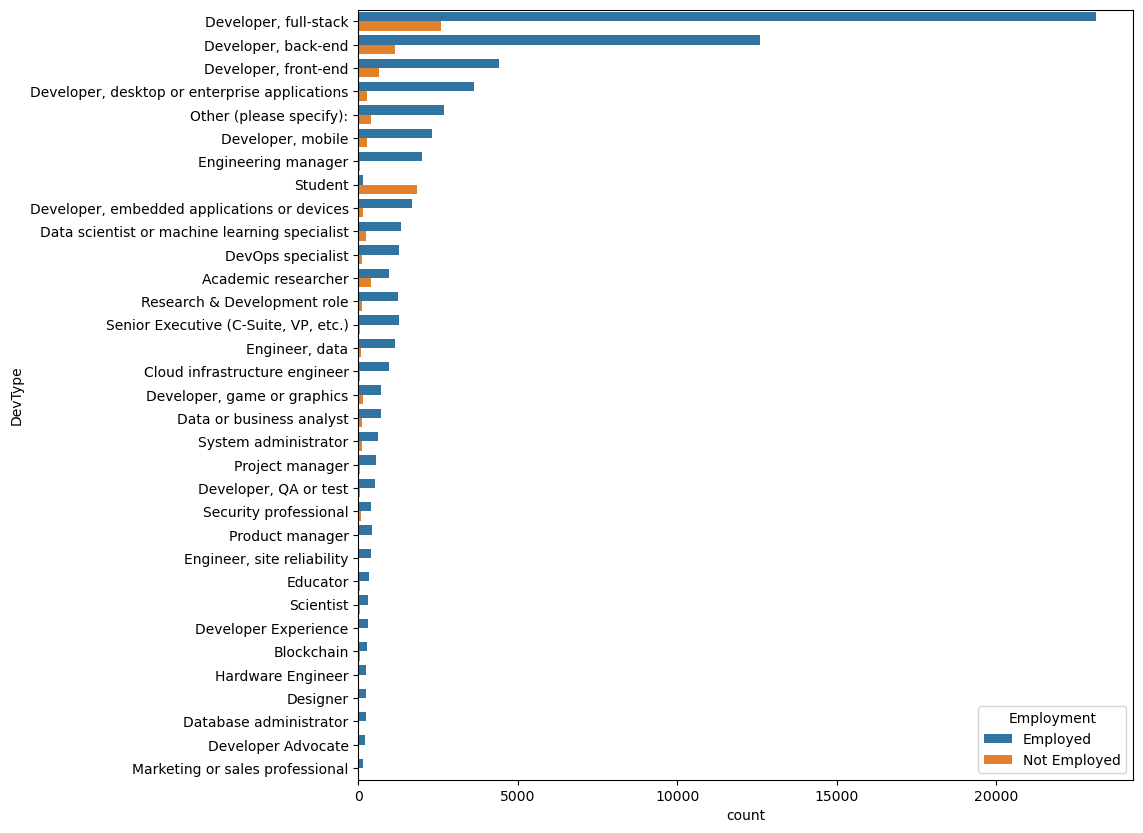

In [88]:
plt.figure(figsize=(10, 10))
sns.countplot(y = 'DevType', data = df2,hue = 'Employment', order = df2['DevType'].value_counts().index)

# Hypothesis testing

In [89]:
df3 = df.copy()
df3

,ResponseId,MainBranch,Age,Employment,RemoteWork,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,LearnCodeCoursesCert,...,Currency,CompTotal,LanguageHaveWorkedWith,DatabaseHaveWorkedWith,PlatformHaveWorkedWith,WebframeHaveWorkedWith,OpSysPersonal use,OpSysProfessional use,AISelect,CompTotal_USD
0,1,None of these,18-24 years old,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,No CompTotal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Boots...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;Friend or fam...,Formal documentation provided by the owner of ...,Other,...,USD\tUnited States dollar,2.850000e+05,HTML/CSS;JavaScript;Python,Supabase,Amazon Web Services (AWS);Netlify;Vercel,Next.js;React;Remix;Vue.js,iOS;iPadOS;MacOS;Windows;Windows Subsystem for...,MacOS;Windows;Windows Subsystem for Linux (WSL),Yes,285000.0
2,3,I am a developer by profession,45-54 years old,Employed,"Hybrid (some remote, some in-person)",Hobby;Professional development or self-paced l...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Formal documentation provided by the owner of ...,NaN,...,USD\tUnited States dollar,2.500000e+05,Bash/Shell (all shells);Go,NaN,Amazon Web Services (AWS);Google Cloud;OpenSta...,NaN,MacOS;Other Linux-based,MacOS;Other Linux-based,"No, and I don't plan to",250000.0
3,4,I am a developer by profession,25-34 years old,Employed,"Hybrid (some remote, some in-person)",Hobby,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Friend or family member;Other online...,Formal documentation provided by the owner of ...,NaN,...,USD\tUnited States dollar,1.560000e+05,Bash/Shell (all shells);HTML/CSS;JavaScript;PH...,PostgreSQL;Redis,Cloudflare;Heroku,Node.js;React;Ruby on Rails;Vue.js;WordPress,iOS;iPadOS;MacOS,iOS;iPadOS;MacOS,"No, and I don't plan to",156000.0
4,5,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Contribute to open-source projects;Profe...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Online Courses or Certi...,Formal documentation provided by the owner of ...,Other;Codecademy;edX,...,PHP\tPhilippine peso,1.320000e+06,HTML/CSS;JavaScript;TypeScript,BigQuery;Elasticsearch;MongoDB;PostgreSQL,Amazon Web Services (AWS);Firebase;Heroku;Netl...,Express;Gatsby;NestJS;Next.js;Node.js;React,Other (Please Specify):,Other (Please Specify):,Yes,22440.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89179,89180,I am a developer by profession,25-34 years old,Employed,Remote,Hobby;Bootstrapping a business;Freelance/contr...,"Associate degree (A.A., A.S., etc.)",Online Courses or Certification;Other online r...,Formal documentation provided by the owner of ...,Udemy,...,BRL\tBrazilian real,2.000000e+05,HTML/CSS;Java;JavaScript;SQL;TypeScript,MongoDB;MySQL;PostgreSQL;SQLite,Digital Ocean;Firebase;Google Cloud;Heroku;Vercel,Angular;AngularJS;Express;jQuery;Node.js;Nuxt....,Android;Windows,Android;Ubuntu;Windows,Yes,36000.0
89180,89181,I am a developer by profession,18-24 years old,Not Employed,"Hybrid (some remote, some in-person)",School or academic work,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Colleague;Online Courses or Certification;Othe...,Formal documentation provided by the owner of ...,NaN,...,No CompTotal,0.000000e+00,Dart;Java;Python;SQL,PostgreSQL,NaN,Spring Boot,Windows,Windows,Yes,0.0
89181,89182,I code primarily as a hobby,Prefer not to say,Employed,NaN,NaN,Something else,Books / Physical media;Hackathons (virtual or ...,NaN,Codecademy;Coursera,...,No CompTotal,0.000000e+00,Assembly;Bash/Shell (all shells);C;C#;Python;R...,SQLite,Amazon Web Services (AWS),NaN,Windows,NaN,"No, but I plan to soon",0.0
89182,89183,I am a developer by profession,Under 18 years old,Not Employed,"Hybrid (some remote, some in-person)",Hobby;School or academic work,"Secondary school (e.g. Amer

In [90]:
df3.isnull().sum()

ResponseId                    0
MainBranch                    0
Age                           0
Employment                 1286
RemoteWork                15374
CodingActivities          15420
EdLevel                    1211
LearnCode                  1521
LearnCodeOnline           19100
LearnCodeCoursesCert      52108
YearsCode                  1749
YearsCodePro              23048
DevType                   12312
OrgSize                    5110
Country                    1211
Currency                      0
CompTotal                  1274
LanguageHaveWorkedWith     2044
DatabaseHaveWorkedWith    15749
PlatformHaveWorkedWith    25556
WebframeHaveWorkedWith    22246
OpSysPersonal use          2627
OpSysProfessional use     10597
AISelect                   1211
CompTotal_USD              1274
dtype: int64

In [91]:
temp = df3.dropna(subset = ['LearnCode'])
df3.isnull().sum()

ResponseId                    0
MainBranch                    0
Age                           0
Employment                 1286
RemoteWork                15374
CodingActivities          15420
EdLevel                    1211
LearnCode                  1521
LearnCodeOnline           19100
LearnCodeCoursesCert      52108
YearsCode                  1749
YearsCodePro              23048
DevType                   12312
OrgSize                    5110
Country                    1211
Currency                      0
CompTotal                  1274
LanguageHaveWorkedWith     2044
DatabaseHaveWorkedWith    15749
PlatformHaveWorkedWith    25556
WebframeHaveWorkedWith    22246
OpSysPersonal use          2627
OpSysProfessional use     10597
AISelect                   1211
CompTotal_USD              1274
dtype: int64

In [92]:
temp.isnull().sum()

ResponseId                    0
MainBranch                    0
Age                           0
Employment                   66
RemoteWork                14099
CodingActivities          14132
EdLevel                       0
LearnCode                     0
LearnCodeOnline           17579
LearnCodeCoursesCert      50587
YearsCode                   425
YearsCodePro              21675
DevType                   10973
OrgSize                    3811
Country                       0
Currency                      0
CompTotal                    54
LanguageHaveWorkedWith      795
DatabaseHaveWorkedWith    14430
PlatformHaveWorkedWith    24212
WebframeHaveWorkedWith    20900
OpSysPersonal use          1343
OpSysProfessional use      9286
AISelect                      0
CompTotal_USD                54
dtype: int64

In [93]:
temp = temp['LearnCode'].str.get_dummies(';')
temp

,Books / Physical media,Coding Bootcamp,Colleague,Friend or family member,Hackathons (virtual or in-person),On the job training,Online Courses or Certification,Other (please specify):,"Other online resources (e.g., videos, blogs, forum)","School (i.e., University, College, etc)"
1,1,0,1,1,1,1,1,0,1,1
2,1,0,1,0,0,1,0,0,1,1
3,0,0,1,1,0,0,0,0,1,1
4,1,0,0,0,0,0,1,0,1,1
5,1,0,1,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...
89179,0,0,0,0,0,0,1,0,1,0
89180,0,0,1,0,0,0,1,0,1,1
89181,1,0,0,0,1,0,1,0,1,1
89182,0,0,0,0,0,0,1,0,1,1


## Hypothesis testing on learning to code using online resources

In [94]:
import scipy.stats as stats
# Null hypothesis-There is no change in the percentage of people using online resources to learn coding from 2021 to 2023.
# Alternate hypothesis-There is a change in the percentage of people using online resources to learn coding from 2021 tp 2023.
n = len(temp[temp['Other online resources (e.g., videos, blogs, forum)'] == 1])
total = len(temp)
stats.binom_test(n,total,p=0.60,alternative = 'two-sided')
# p-value is less than 0.05, therefore we reject the null hypthesis and conclude that there is a statistically significant
# change in the percentage of people using online resources to learn coding from 2021 to 2023 

C:\Users\uthay\AppData\Local\Temp\ipykernel_8016\2951960763.py:6: DeprecationWarning: 'binom_test' is deprecated in favour of 'binomtest' from version 1.7.0 and will be removed in Scipy 1.12.0.
  stats.binom_test(n,total,p=0.60,alternative = 'two-sided')
C:\Users\uthay\anaconda3\envs\py38\lib\site-packages\scipy\stats\_discrete_distns.py:77: RuntimeWarning: divide by zero encountered in _binom_pdf
  return _boost._binom_pdf(x, n, p)


2.5e-323

In [95]:
#Null hypothesis-There is no increase in the percentage of people using online resources to learn coding from 2021 to 2023.
#Alternate hypothesis-There is an increase in the percentage of people using online resources to learn coding from 2021 to 2023.
n = len(temp[temp['Other online resources (e.g., videos, blogs, forum)'] == 1])
total = len(temp)
stats.binom_test(n,total,p=0.60,alternative = 'greater')
#p-value is less than 0.05, therefore we reject the null hypthesis and conclude that there is a statistically significant
#increase in the percentage of people using online resources to learn coding from 2021 to 2023 

C:\Users\uthay\AppData\Local\Temp\ipykernel_8016\4100946146.py:5: DeprecationWarning: 'binom_test' is deprecated in favour of 'binomtest' from version 1.7.0 and will be removed in Scipy 1.12.0.
  stats.binom_test(n,total,p=0.60,alternative = 'greater')


0.0

## Hypothesis testing on employment

In [96]:
#Null hypothesis-There is no decrease in the percentage of people being employed from 2021 to 2023
#Alternate hypothesis-There is a decrease in the percentage of people being employed from 2021 to 2023
temp2 = df3.dropna(subset = ['Employment'])
n = len(temp2[temp2['Employment'] == 'Employed'])
total = len(temp2)
stats.binom_test(n,total,p=0.81,alternative = 'less')

C:\Users\uthay\AppData\Local\Temp\ipykernel_8016\1226271851.py:6: DeprecationWarning: 'binom_test' is deprecated in favour of 'binomtest' from version 1.7.0 and will be removed in Scipy 1.12.0.
  stats.binom_test(n,total,p=0.81,alternative = 'less')


1.116921724080611e-86

## Hypothesis testing on the annual compensation of Master's degree devs and Ph.d devs.

In [97]:
#Null hypethesis-There is no difference in the salaries between Masters devs and Ph.D devs
#Alternate hypothesis-There is a difference in the salaries between Masters devs and Ph.D devs 
temp3 = df3.dropna(subset = ['CompTotal_USD'])
temp3 = temp3[(temp3['CompTotal_USD'] >= 40000) & (temp3['CompTotal_USD'] <= 500000)]
m = temp3[temp3['EdLevel'] == 'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)']['CompTotal_USD']
p = temp3[temp3['EdLevel'] == 'Professional degree (JD, MD, Ph.D, Ed.D, etc.)']['CompTotal_USD']
stats.ttest_ind(m,p, equal_var = False)

Ttest_indResult(statistic=-6.7391039662403465, pvalue=2.0028060325101793e-11)

## Hypothesis testing on the annual compensation of Master's degree devs and Bachelor degree devs.

In [98]:
#Null hypethesis-There is no difference in the salaries between Masters devs and Bachelor devs
#Alternate hypothesis-There is a difference in the salaries between Masters devs and Bachelor devs 
temp4 = df3.dropna(subset = ['CompTotal_USD'])
temp4 = temp4[(temp4['CompTotal_USD'] >= 40000) & (temp4['CompTotal_USD'] <= 500000)]
m = temp4[temp4['EdLevel'] == 'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)']['CompTotal_USD']
b = temp4[temp4['EdLevel'] == 'Bachelor’s degree (B.A., B.S., B.Eng., etc.)']['CompTotal_USD']
stats.ttest_ind(m,b, equal_var = True)

Ttest_indResult(statistic=-13.95127764601034, pvalue=4.3486338494436723e-44)

In [99]:
from statsmodels.stats import oneway as oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
temp3 = df3.dropna(subset = ['CompTotal_USD'])
temp3 = temp3[(temp3['CompTotal_USD'] >= 40000) & (temp3['CompTotal_USD'] <= 500000)]
m = temp3[temp3['EdLevel'] == 'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)']['CompTotal_USD']
p = temp3[temp3['EdLevel'] == 'Professional degree (JD, MD, Ph.D, Ed.D, etc.)']['CompTotal_USD']
stats.f_oneway(m,p)

F_onewayResult(statistic=58.363907066093084, pvalue=2.3354091468921513e-14)

In [100]:
temp3 = df3.dropna(subset = ['LearnCodeOnline'])
#temp3 = temp3['LearnCodeOnline'].str.get_dummies(';')